In [1]:
import duckdb

## 1). Subsetting required columns

**original list of columns**

["resp_pkts", "service", "orig_ip_bytes", "local_resp", "missed_bytes", "proto", "duration", "conn_state", "dest_ip_zeek", "orig_pkts", 
 "community_id", "resp_ip_bytes", "dest_port_zeek", "orig_bytes", "local_orig", "datetime", "history", "resp_bytes", "uid", "src_port_zeek", 
 "ts", "src_ip_zeek", "label_tactic", "source_period", "label_technique", "label_cve", "label_binary", "vlan"]

 we need 19 of them, so excluding remaning

In [2]:
source_path = "combined_uwf_dataset.parquet" ## combined raw logs for all years
output_path = "uwf_required_columns.parquet"

In [3]:
## connecting to duckdb
con = duckdb.connect()

con.execute(f"""
COPY (
    SELECT
        datetime,
        source_period,
        src_ip_zeek,
        dest_ip_zeek,
        dest_port_zeek,
        proto,
        conn_state,
        service,
        duration,
        orig_bytes,
        resp_bytes,
        orig_pkts,
        resp_pkts,
        orig_ip_bytes,
        resp_ip_bytes,
        missed_bytes,
        label_binary,
        label_tactic,
        label_technique
    FROM read_parquet('{source_path}')
)
TO '{output_path}'
(FORMAT PARQUET, COMPRESSION ZSTD);
""")

con.close()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [4]:
## checking row-count and time coverage

con = duckdb.connect()

result = con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        MIN(datetime) AS earliest_datetime,
        MAX(datetime) AS latest_datetime,
        COUNT(DISTINCT source_period) AS number_of_periods
    FROM read_parquet('uwf_required_columns.parquet');
""").fetchone()

print("Total rows:", result[0])
print("Earliest datetime:", result[1])
print("Latest datetime:", result[2])
print("Number of source periods:", result[3])

con.close()

Total rows: 27111594
Earliest datetime: 2021-12-17 07:00:45.213000
Latest datetime: 2025-07-31 14:56:10.005000
Number of source periods: 40


In [5]:
## checking datatype of the columns


con = duckdb.connect()

schema = con.execute("""
    DESCRIBE
    SELECT *
    FROM read_parquet('uwf_required_columns.parquet');
""").fetchall()

for column_name, column_type, *_ in schema:
    print(f"{column_name}: {column_type}")

con.close()

datetime: TIMESTAMP_NS
source_period: VARCHAR
src_ip_zeek: VARCHAR
dest_ip_zeek: VARCHAR
dest_port_zeek: INTEGER
proto: VARCHAR
conn_state: VARCHAR
service: VARCHAR
duration: DOUBLE
orig_bytes: DOUBLE
resp_bytes: DOUBLE
orig_pkts: INTEGER
resp_pkts: INTEGER
orig_ip_bytes: INTEGER
resp_ip_bytes: INTEGER
missed_bytes: INTEGER
label_binary: VARCHAR
label_tactic: VARCHAR
label_technique: VARCHAR


In [6]:
## checking missing values


con = duckdb.connect()

missing_values = con.execute("""
    SELECT
        COUNT(*) FILTER (WHERE datetime IS NULL) AS datetime_missing,
        COUNT(*) FILTER (WHERE source_period IS NULL OR TRIM(source_period) = '') AS source_period_missing,
        COUNT(*) FILTER (WHERE src_ip_zeek IS NULL OR TRIM(src_ip_zeek) = '') AS src_ip_missing,
        COUNT(*) FILTER (WHERE dest_ip_zeek IS NULL OR TRIM(dest_ip_zeek) = '') AS dest_ip_missing,
        COUNT(*) FILTER (WHERE dest_port_zeek IS NULL) AS dest_port_missing,
        COUNT(*) FILTER (WHERE proto IS NULL OR TRIM(proto) = '') AS proto_missing,
        COUNT(*) FILTER (WHERE conn_state IS NULL OR TRIM(conn_state) = '') AS conn_state_missing,
        COUNT(*) FILTER (WHERE service IS NULL OR TRIM(service) = '') AS service_missing,
        COUNT(*) FILTER (WHERE duration IS NULL) AS duration_missing,
        COUNT(*) FILTER (WHERE orig_bytes IS NULL) AS orig_bytes_missing,
        COUNT(*) FILTER (WHERE resp_bytes IS NULL) AS resp_bytes_missing,
        COUNT(*) FILTER (WHERE orig_pkts IS NULL) AS orig_pkts_missing,
        COUNT(*) FILTER (WHERE resp_pkts IS NULL) AS resp_pkts_missing,
        COUNT(*) FILTER (WHERE orig_ip_bytes IS NULL) AS orig_ip_bytes_missing,
        COUNT(*) FILTER (WHERE resp_ip_bytes IS NULL) AS resp_ip_bytes_missing,
        COUNT(*) FILTER (WHERE missed_bytes IS NULL) AS missed_bytes_missing,
        COUNT(*) FILTER (WHERE label_binary IS NULL OR TRIM(label_binary) = '') AS label_binary_missing,
        COUNT(*) FILTER (WHERE label_tactic IS NULL OR TRIM(label_tactic) = '') AS label_tactic_missing,
        COUNT(*) FILTER (WHERE label_technique IS NULL OR TRIM(label_technique) = '') AS label_technique_missing
    FROM read_parquet('uwf_required_columns.parquet');
""").fetchone()

column_names = [
    "datetime",
    "source_period",
    "src_ip",
    "dest_ip",
    "dest_port",
    "proto",
    "conn_state",
    "service",
    "duration",
    "orig_bytes",
    "resp_bytes",
    "orig_pkts",
    "resp_pkts",
    "orig_ip_bytes",
    "resp_ip_bytes",
    "missed_bytes",
    "label_binary",
    "label_tactic",
    "label_technique"
]

for name, count in zip(column_names, missing_values):
    print(f"{name}: {count}")

con.close()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

datetime: 0
source_period: 0
src_ip: 0
dest_ip: 0
dest_port: 0
proto: 0
conn_state: 0
service: 12262556
duration: 2880342
orig_bytes: 2880342
resp_bytes: 2880342
orig_pkts: 0
resp_pkts: 0
orig_ip_bytes: 0
resp_ip_bytes: 0
missed_bytes: 0
label_binary: 0
label_tactic: 0
label_technique: 0


In [7]:
## Inspecting label values and their frequencies


con = duckdb.connect()

label_summary = con.execute("""
    SELECT
        'binary' AS label_type,
        CAST(label_binary AS VARCHAR) AS label_value,
        COUNT(*) AS row_count
    FROM read_parquet('uwf_required_columns.parquet')
    GROUP BY label_binary

    UNION ALL

    SELECT
        'tactic' AS label_type,
        CAST(label_tactic AS VARCHAR) AS label_value,
        COUNT(*) AS row_count
    FROM read_parquet('uwf_required_columns.parquet')
    GROUP BY label_tactic

    UNION ALL

    SELECT
        'technique' AS label_type,
        CAST(label_technique AS VARCHAR) AS label_value,
        COUNT(*) AS row_count
    FROM read_parquet('uwf_required_columns.parquet')
    GROUP BY label_technique

    ORDER BY label_type, row_count DESC;
""").fetchall()

for row in label_summary:
    print(row)

con.close()

('binary', 'unknown', 18562468)
('binary', 'False', 4274703)
('binary', 'True', 4241370)
('binary', 'Duplicate', 33053)
('tactic', 'none', 13556302)
('tactic', 'Reconnaissance', 10519364)
('tactic', 'Discovery', 1829544)
('tactic', 'Credential Access', 871220)
('tactic', 'Resource Development', 275474)
('tactic', 'Privilege Escalation', 20968)
('tactic', 'Defense Evasion', 20954)
('tactic', 'Initial Access', 10720)
('tactic', 'Persistence', 6059)
('tactic', 'Exfiltration', 566)
('tactic', 'Lateral Movement', 370)
('tactic', 'Execution', 32)
('tactic', 'Command and Control', 20)
('tactic', 'Collection', 1)
('technique', 'unknown', 18562468)
('technique', 'none', 4274703)
('technique', 'T1046', 1779059)
('technique', 'T1595', 1197737)
('technique', 'T1110', 871188)
('technique', 'T1587', 275471)
('technique', 'Duplicate', 33053)
('technique', 'T1018', 30774)
('technique', 'T1592', 21405)
('technique', 'T1590', 21208)
('technique', 'T1016', 17625)
('technique', 'T1548', 14902)
('technique

## 2). Cleaning the target variables

Targets: Label Binary , Label Technique, Label Tactic

- Creating three new columns with processed targets: binary_target, tactic_target, mitre_target
- binary_target = 0-normal, 1- attack, duplicates are removed and for unknown: if tactic present then 1, otherwise 0
- tactic_target = Keeping values only for attack rows, Normal events have NULL
- mitre_target = Non-attack, missing, none, and invalid values receive NULL. For attack, keeps only valid MITRE IDs

In [8]:
con = duckdb.connect()


In [9]:
con.execute("""
CREATE OR REPLACE VIEW cleaned_logs AS

WITH labeled_rows AS (
    SELECT
        *,

        CASE
            WHEN label_binary = 'True' THEN 1
            WHEN label_binary = 'False' THEN 0

            WHEN label_binary = 'unknown'
                 AND LOWER(TRIM(label_tactic)) = 'none'
                THEN 0

            WHEN label_binary = 'unknown'
                 AND LOWER(TRIM(label_tactic))
                     NOT IN ('none', 'unknown', '')
                THEN 1

            ELSE NULL
        END AS binary_target

    FROM read_parquet('uwf_required_columns.parquet')
    WHERE label_binary != 'Duplicate'
)

SELECT
    *,

    CASE
        WHEN binary_target = 1
             AND LOWER(TRIM(label_tactic))
                 NOT IN ('none', 'unknown', '')
            THEN TRIM(label_tactic)
        ELSE NULL
    END AS tactic_target,

    CASE
        WHEN binary_target = 1
             AND regexp_full_match(
                 TRIM(label_technique),
                 'T[0-9]{4}([.][0-9]{3})?'
             )
            THEN TRIM(label_technique)
        ELSE NULL
    END AS mitre_target

FROM labeled_rows
WHERE binary_target IS NOT NULL;
""")

print("Created view: cleaned_logs")

Created view: cleaned_logs


In [10]:
## validating cleaned targets

target_summary = con.execute("""
    SELECT
        binary_target,
        COUNT(*) AS total_rows,
        COUNT(tactic_target) AS rows_with_tactic,
        COUNT(mitre_target) AS rows_with_mitre
    FROM cleaned_logs
    GROUP BY binary_target
    ORDER BY binary_target;
""").fetchall()

print(
    "binary_target | total_rows | rows_with_tactic | rows_with_mitre"
)

for row in target_summary:
    print(row)

binary_target | total_rows | rows_with_tactic | rows_with_mitre
(0, 13556302, 0, 0)
(1, 13522239, 13522239, 4241370)


For attack samples, some MITRE information is not present

## 3). Analyzing 5-min window aggregation

5-minute window is suitable if it contains enough communication activity to form a graph, while not mixing too many unrelated activities together.

In [11]:
five_minute_evidence = con.execute("""
    WITH edge_events AS (
        SELECT
            TIME_BUCKET(INTERVAL '5 minutes', datetime) AS window_start,
            src_ip_zeek,
            dest_ip_zeek,

            COUNT(*) AS event_count,
            MIN(binary_target) AS minimum_binary_target,
            MAX(binary_target) AS maximum_binary_target,
            COUNT(DISTINCT mitre_target) AS technique_count,
            COUNT(DISTINCT tactic_target) AS tactic_count

        FROM cleaned_logs

        GROUP BY
            window_start,
            src_ip_zeek,
            dest_ip_zeek
    ),

    window_summary AS (
        SELECT
            window_start,
            SUM(event_count) AS raw_event_count,
            COUNT(*) AS edge_count,
            COUNT(DISTINCT src_ip_zeek) AS source_ip_count,
            COUNT(DISTINCT dest_ip_zeek) AS destination_ip_count,

            SUM(
                CASE
                    WHEN minimum_binary_target != maximum_binary_target
                    THEN 1 ELSE 0
                END
            ) AS mixed_label_edges,

            SUM(
                CASE
                    WHEN technique_count > 1
                    THEN 1 ELSE 0
                END
            ) AS multi_technique_edges,

            SUM(
                CASE
                    WHEN tactic_count > 1
                    THEN 1 ELSE 0
                END
            ) AS multi_tactic_edges

        FROM edge_events
        GROUP BY window_start
    )

    SELECT
        COUNT(*) AS total_5min_windows,

        ROUND(AVG(raw_event_count), 2) AS average_events_per_window,
        MEDIAN(raw_event_count) AS median_events_per_window,

        ROUND(AVG(edge_count), 2) AS average_edges_per_window,
        MEDIAN(edge_count) AS median_edges_per_window,

        ROUND(AVG(source_ip_count), 2) AS average_source_ips_per_window,
        ROUND(AVG(destination_ip_count), 2) AS average_destination_ips_per_window,

        SUM(
            CASE
                WHEN source_ip_count > 1
                 AND destination_ip_count > 1
                THEN 1 ELSE 0
            END
        ) AS windows_with_multiple_sources_and_destinations,

        ROUND(
            100.0 * SUM(
                CASE
                    WHEN source_ip_count > 1
                     AND destination_ip_count > 1
                    THEN 1 ELSE 0
                END
            ) / COUNT(*),
            2
        ) AS percentage_interconnected_windows,

        SUM(mixed_label_edges) AS mixed_label_edges,
        SUM(multi_technique_edges) AS multi_technique_edges,
        SUM(multi_tactic_edges) AS multi_tactic_edges

    FROM window_summary;
""").fetchone()

column_names = [
    "total_5min_windows",
    "average_events_per_window",
    "median_events_per_window",
    "average_edges_per_window",
    "median_edges_per_window",
    "average_source_ips_per_window",
    "average_destination_ips_per_window",
    "windows_with_multiple_sources_and_destinations",
    "percentage_interconnected_windows",
    "mixed_label_edges",
    "multi_technique_edges",
    "multi_tactic_edges"
]

for name, value in zip(column_names, five_minute_evidence):
    print(f"{name}: {value}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

total_5min_windows: 25186
average_events_per_window: 1075.14
median_events_per_window: 521.0
average_edges_per_window: 26.92
median_edges_per_window: 22.0
average_source_ips_per_window: 18.1
average_destination_ips_per_window: 14.79
windows_with_multiple_sources_and_destinations: 23968
percentage_interconnected_windows: 95.16
mixed_label_edges: 0
multi_technique_edges: 1762
multi_tactic_edges: 1460


- Median of 521 events per window provides enough activity.
- Median of 22 IP-to-IP edges creates a meaningful graph.
- About 18 source IPs and 15 destination IPs are active per window.
- 95.16% of windows contain multiple sources and destinations.
- 0 mixed-label edges means no IP pair contains both benign and attack events within the same 5-minute window.
- 1,762 edges contain multiple MITRE techniques.
- 1,460 edges contain multiple tactics

### Visualizing Timed-window interaction between IPs

Busiest 5-minute window: 2022-02-10 17:45:00


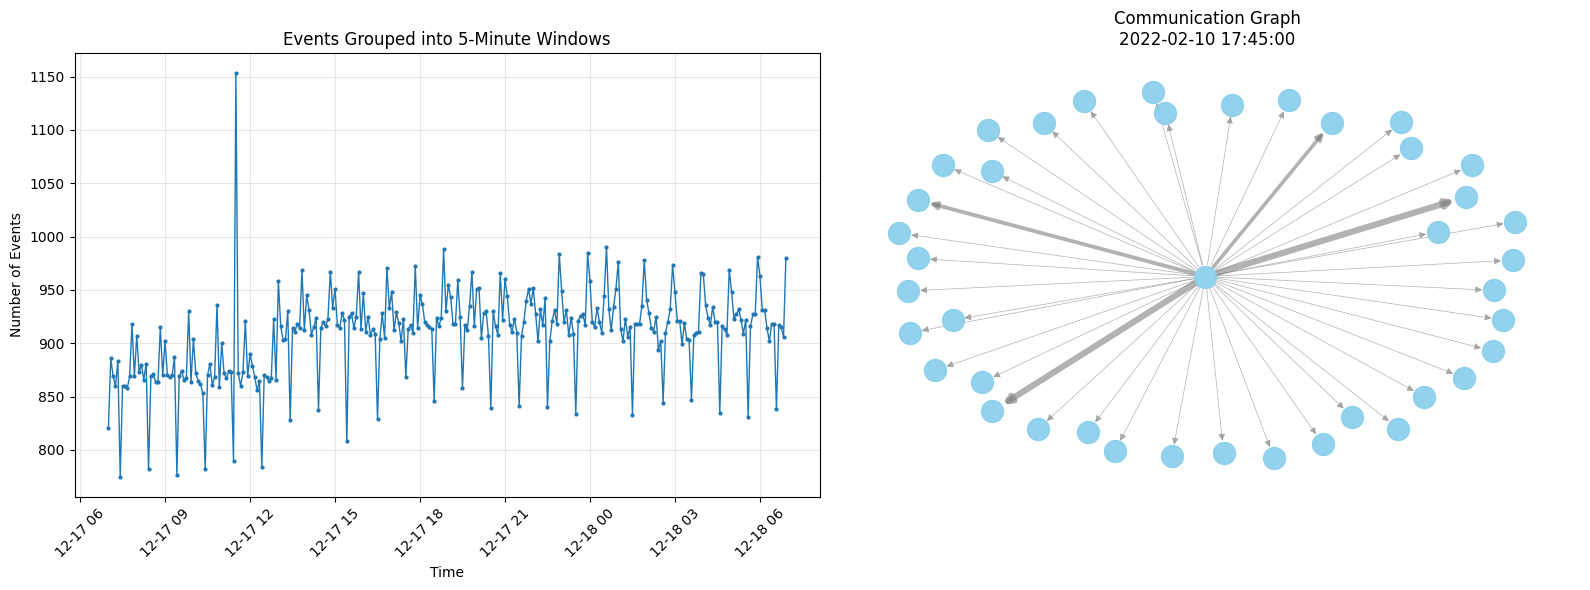

In [12]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx



# Count events and communication edges in each 5-minute window
window_counts = con.execute("""
    SELECT
        TIME_BUCKET(INTERVAL '5 minutes', datetime) AS window_start,
        COUNT(*) AS event_count,
        COUNT(DISTINCT src_ip_zeek) AS unique_source_ips,
        COUNT(DISTINCT dest_ip_zeek) AS unique_destination_ips,
        COUNT(DISTINCT (src_ip_zeek, dest_ip_zeek)) AS edge_count
    FROM read_parquet('uwf_required_columns.parquet')
    GROUP BY window_start
    ORDER BY window_start;
""").df()

# Select the busiest 5-minute window
busiest_window = window_counts.loc[
    window_counts["event_count"].idxmax(),
    "window_start"
]

print("Busiest 5-minute window:", busiest_window)

# Retrieve the communication edges from that window
edge_counts = con.execute("""
    SELECT
        src_ip_zeek,
        dest_ip_zeek,
        COUNT(*) AS connection_count
    FROM read_parquet('uwf_required_columns.parquet')
    WHERE TIME_BUCKET(INTERVAL '5 minutes', datetime) = ?
    GROUP BY src_ip_zeek, dest_ip_zeek
    ORDER BY connection_count DESC
    LIMIT 40;
""", [busiest_window]).df()



# Keep only the first 24 hours for a readable time-window plot
first_window = window_counts["window_start"].min()
one_day_data = window_counts[
    window_counts["window_start"] < first_window + pd.Timedelta(days=1)
]

# Create the communication graph
graph = nx.from_pandas_edgelist(
    edge_counts,
    source="src_ip_zeek",
    target="dest_ip_zeek",
    edge_attr="connection_count",
    create_using=nx.DiGraph()
)

positions = nx.spring_layout(graph, seed=42)

plt.figure(figsize=(16, 6))

# Plot 1: events grouped into 5-minute windows
plt.subplot(1, 2, 1)

plt.plot(
    one_day_data["window_start"],
    one_day_data["event_count"],
    marker="o",
    markersize=2,
    linewidth=1
)

plt.title("Events Grouped into 5-Minute Windows")
plt.xlabel("Time")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

# Plot 2: communication graph for one 5-minute window
plt.subplot(1, 2, 2)

edge_widths = [
    0.5 + graph[u][v]["connection_count"] / edge_counts["connection_count"].max() * 4
    for u, v in graph.edges()
]

nx.draw_networkx_nodes(
    graph,
    positions,
    node_size=250,
    node_color="skyblue",
    alpha=0.9
)

nx.draw_networkx_edges(
    graph,
    positions,
    width=edge_widths,
    edge_color="gray",
    arrows=True,
    alpha=0.6,
    arrowsize=10
)

plt.title(f"Communication Graph\n{busiest_window}")
plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
import duckdb



candidate_windows = con.execute("""
    WITH window_edges AS (
        SELECT
            TIME_BUCKET(INTERVAL '5 minutes', datetime) AS window_start,
            src_ip_zeek,
            dest_ip_zeek
        FROM read_parquet('uwf_required_columns.parquet')
        GROUP BY
            window_start,
            src_ip_zeek,
            dest_ip_zeek
    )

    SELECT
        window_start,
        COUNT(*) AS total_edges,
        COUNT(DISTINCT src_ip_zeek) AS unique_sources,
        COUNT(DISTINCT dest_ip_zeek) AS unique_destinations
    FROM window_edges
    GROUP BY window_start
    HAVING COUNT(DISTINCT src_ip_zeek) BETWEEN 2 AND 4
       AND COUNT(DISTINCT dest_ip_zeek) >= 5
    ORDER BY
        unique_sources DESC,
        unique_destinations DESC,
        total_edges DESC
    LIMIT 20;
""").df()

display(candidate_windows)

,window_start,total_edges,unique_sources,unique_destinations
0,2024-02-28 04:00:00,46,4,46
1,2024-03-14 10:00:00,46,4,46
2,2024-03-17 13:00:00,46,4,46
3,2024-03-02 05:45:00,42,4,42
4,2024-03-17 14:20:00,42,4,42
5,2024-03-19 06:25:00,42,4,42
6,2024-03-03 08:50:00,42,4,42
7,2024-03-18 15:35:00,33,4,33
8,2024-03-17 11:35:00,32,4,32
9,2024-03-24 09:40:00,32,4,32


In [14]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# SELECTED_WINDOW = "2022-02-10 17:45:00"
SELECTED_WINDOW = "2025-05-25 04:40:00"
# SELECTED_WINDOW = "2024-03-14 10:00:00"



interactions = con.execute("""
    SELECT
        src_ip_zeek,
        dest_ip_zeek,
        COUNT(*) AS connection_count,
        SUM(COALESCE(orig_bytes, 0)) AS total_orig_bytes,
        SUM(COALESCE(resp_bytes, 0)) AS total_resp_bytes,
        STRING_AGG(DISTINCT proto, ', ') AS protocols
    FROM read_parquet('uwf_required_columns.parquet')
    WHERE TIME_BUCKET(INTERVAL '5 minutes', datetime)
          = CAST(? AS TIMESTAMP)
    GROUP BY
        src_ip_zeek,
        dest_ip_zeek
    ORDER BY connection_count DESC
    LIMIT 30;
""", [SELECTED_WINDOW]).df()



print("Selected window:", SELECTED_WINDOW)
print("Number of displayed interactions:", len(interactions))

display(interactions)

Selected window: 2025-05-25 04:40:00
Number of displayed interactions: 30


,src_ip_zeek,dest_ip_zeek,connection_count,total_orig_bytes,total_resp_bytes,protocols
0,143.88.0.6,143.88.255.10,55,5477.0,0.0,udp
1,143.88.0.10,143.88.255.10,52,5208.0,0.0,udp
2,143.88.0.2,143.88.255.10,49,4504.0,0.0,udp
3,143.88.0.14,143.88.255.10,46,4468.0,0.0,udp
4,143.88.1.18,143.88.255.10,30,2760.0,0.0,udp
5,143.88.4.10,143.88.255.10,28,2518.0,0.0,udp
6,143.88.255.50,143.88.255.1,25,4248.0,0.0,udp
7,143.88.2.10,143.88.255.10,24,2094.0,0.0,udp
8,143.88.3.11,143.88.255.10,24,2214.0,0.0,udp
9,143.88.2.11,143.88.255.10,23,2138.0,0.0,udp


Focal IP: 143.88.255.10


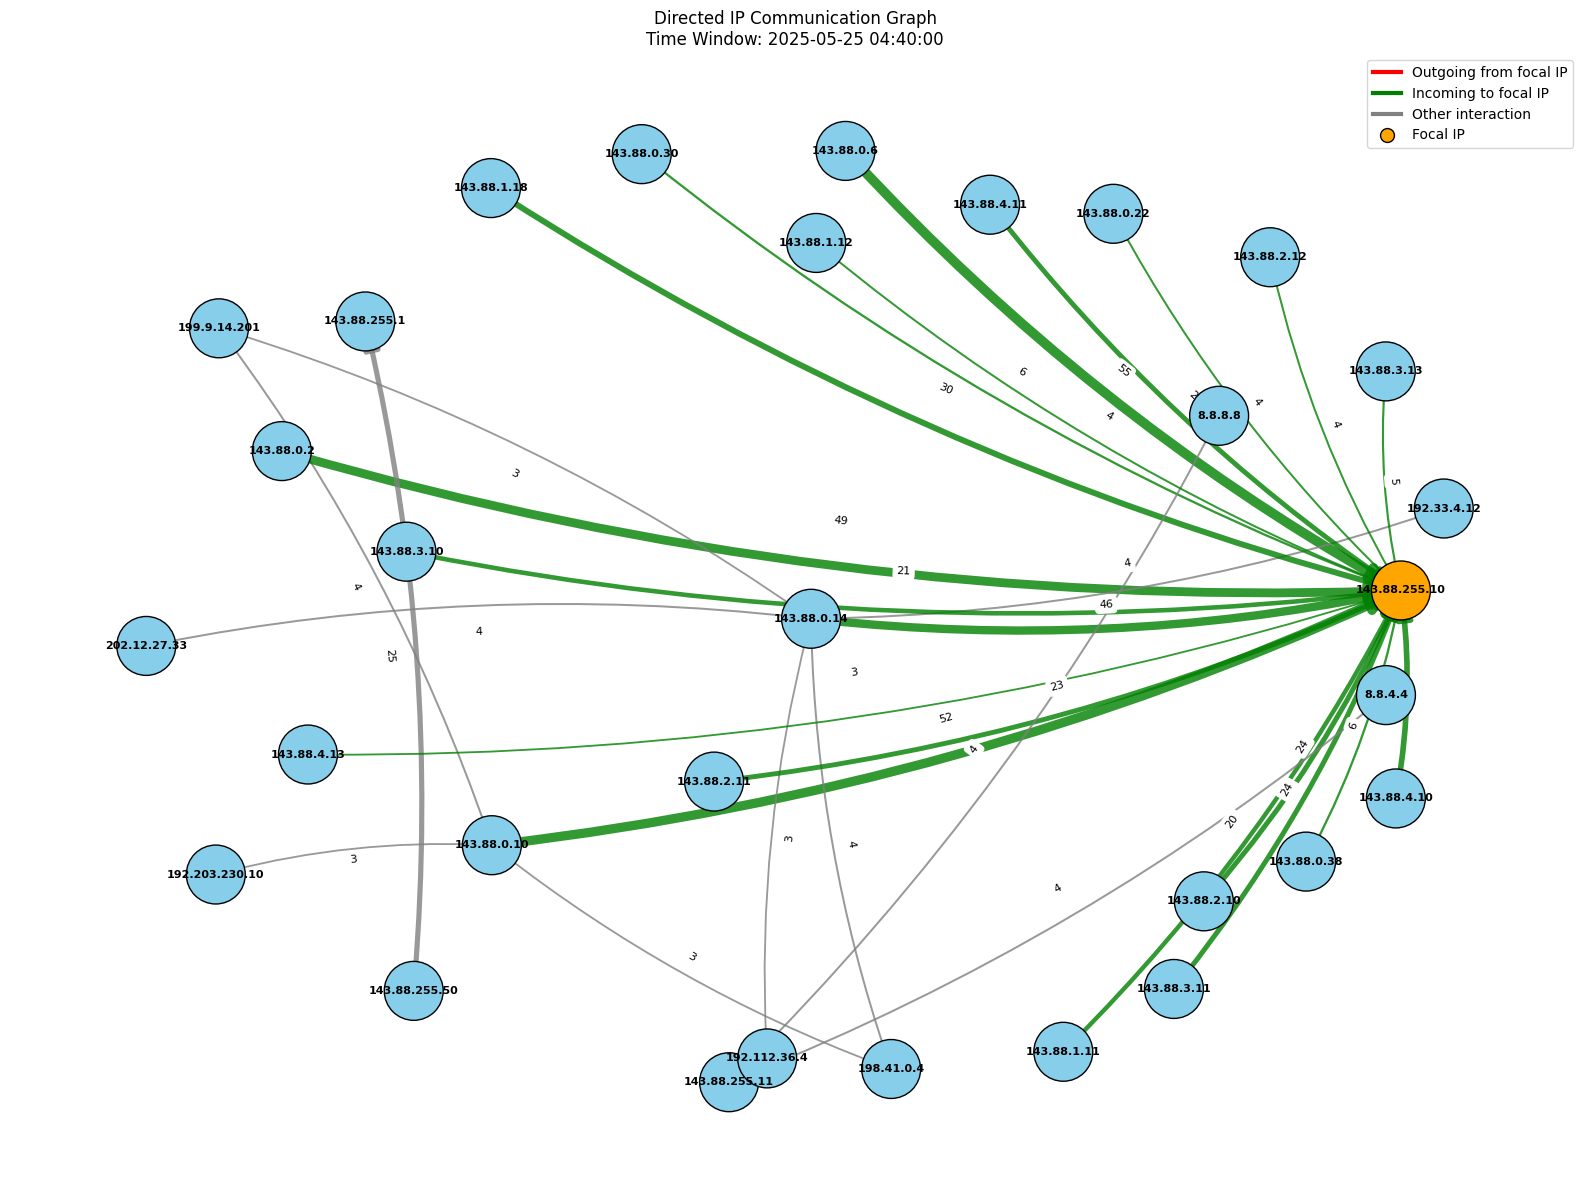

In [15]:
from matplotlib.lines import Line2D

# Create a directed graph
graph = nx.DiGraph()

for _, row in interactions.iterrows():
    graph.add_edge(
        row["src_ip_zeek"],
        row["dest_ip_zeek"],
        connection_count=row["connection_count"]
    )

# Select the most connected IP as the focal IP - IP with most number of connections in that time-window
focal_ip = max(graph.degree(), key=lambda item: item[1])[0]

print("Focal IP:", focal_ip)

# Arrange nodes
positions = nx.spring_layout(graph, seed=42, k=1.5)

maximum_count = interactions["connection_count"].max()

edge_widths = [
    1 + (graph[u][v]["connection_count"] / maximum_count) * 6
    for u, v in graph.edges()
]

# Assign colors based on direction relative to focal IP
edge_colors = []

for u, v in graph.edges():
    if u == focal_ip:
        edge_colors.append("red")       # Outgoing from focal IP
    elif v == focal_ip:
        edge_colors.append("green")     # Incoming to focal IP
    else:
        edge_colors.append("gray")      # Other interactions

plt.figure(figsize=(16, 12))

nx.draw_networkx_nodes(
    graph,
    positions,
    node_color=[
        "orange" if node == focal_ip else "skyblue"
        for node in graph.nodes()
    ],
    node_size=1800,
    edgecolors="black",
    linewidths=1
)

nx.draw_networkx_edges(
    graph,
    positions,
    width=edge_widths,
    edge_color=edge_colors,
    arrows=True,
    arrowsize=22,
    alpha=0.8,
    connectionstyle="arc3,rad=0.08"
)

nx.draw_networkx_labels(
    graph,
    positions,
    font_size=8,
    font_weight="bold"
)

edge_labels = {
    (u, v): graph[u][v]["connection_count"]
    for u, v in graph.edges()
}

nx.draw_networkx_edge_labels(
    graph,
    positions,
    edge_labels=edge_labels,
    font_size=8,
    label_pos=0.5
)

legend_items = [
    Line2D(
        [0], [0],
        color="red",
        lw=3,
        label="Outgoing from focal IP"
    ),
    Line2D(
        [0], [0],
        color="green",
        lw=3,
        label="Incoming to focal IP"
    ),
    Line2D(
        [0], [0],
        color="gray",
        lw=3,
        label="Other interaction"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor="orange",
        markeredgecolor="black",
        markersize=10,
        label="Focal IP"
    )
]

plt.legend(handles=legend_items, loc="best")

plt.title(
    f"Directed IP Communication Graph\n"
    f"Time Window: {SELECTED_WINDOW}"
)

plt.axis("off")
plt.tight_layout()
plt.show()

In [16]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# SELECTED_WINDOW = "2022-02-10 17:45:00"
# SELECTED_WINDOW = "2025-05-25 04:40:00"
SELECTED_WINDOW = "2024-03-14 10:00:00"



interactions = con.execute("""
    SELECT
        src_ip_zeek,
        dest_ip_zeek,
        COUNT(*) AS connection_count,
        SUM(COALESCE(orig_bytes, 0)) AS total_orig_bytes,
        SUM(COALESCE(resp_bytes, 0)) AS total_resp_bytes,
        STRING_AGG(DISTINCT proto, ', ') AS protocols
    FROM read_parquet('uwf_required_columns.parquet')
    WHERE TIME_BUCKET(INTERVAL '5 minutes', datetime)
          = CAST(? AS TIMESTAMP)
    GROUP BY
        src_ip_zeek,
        dest_ip_zeek
    ORDER BY connection_count DESC
    LIMIT 30;
""", [SELECTED_WINDOW]).df()



print("Selected window:", SELECTED_WINDOW)
print("Number of displayed interactions:", len(interactions))

display(interactions)

Selected window: 2024-03-14 10:00:00
Number of displayed interactions: 30


,src_ip_zeek,dest_ip_zeek,connection_count,total_orig_bytes,total_resp_bytes,protocols
0,143.88.9.12,143.88.10.11,138,117433.0,1966373.0,tcp
1,143.88.4.11,143.88.5.11,2,0.0,0.0,tcp
2,143.88.10.12,143.88.11.17,2,0.0,0.0,tcp
3,143.88.4.11,143.88.5.20,2,0.0,0.0,tcp
4,143.88.10.12,143.88.11.3,2,0.0,0.0,tcp
5,143.88.10.12,143.88.11.16,2,0.0,0.0,tcp
6,143.88.4.11,143.88.5.19,2,0.0,0.0,tcp
7,143.88.10.12,143.88.11.8,2,0.0,0.0,tcp
8,143.88.10.12,143.88.11.19,2,0.0,0.0,tcp
9,143.88.4.11,143.88.5.15,2,0.0,0.0,tcp


Focal IP: 143.88.4.11


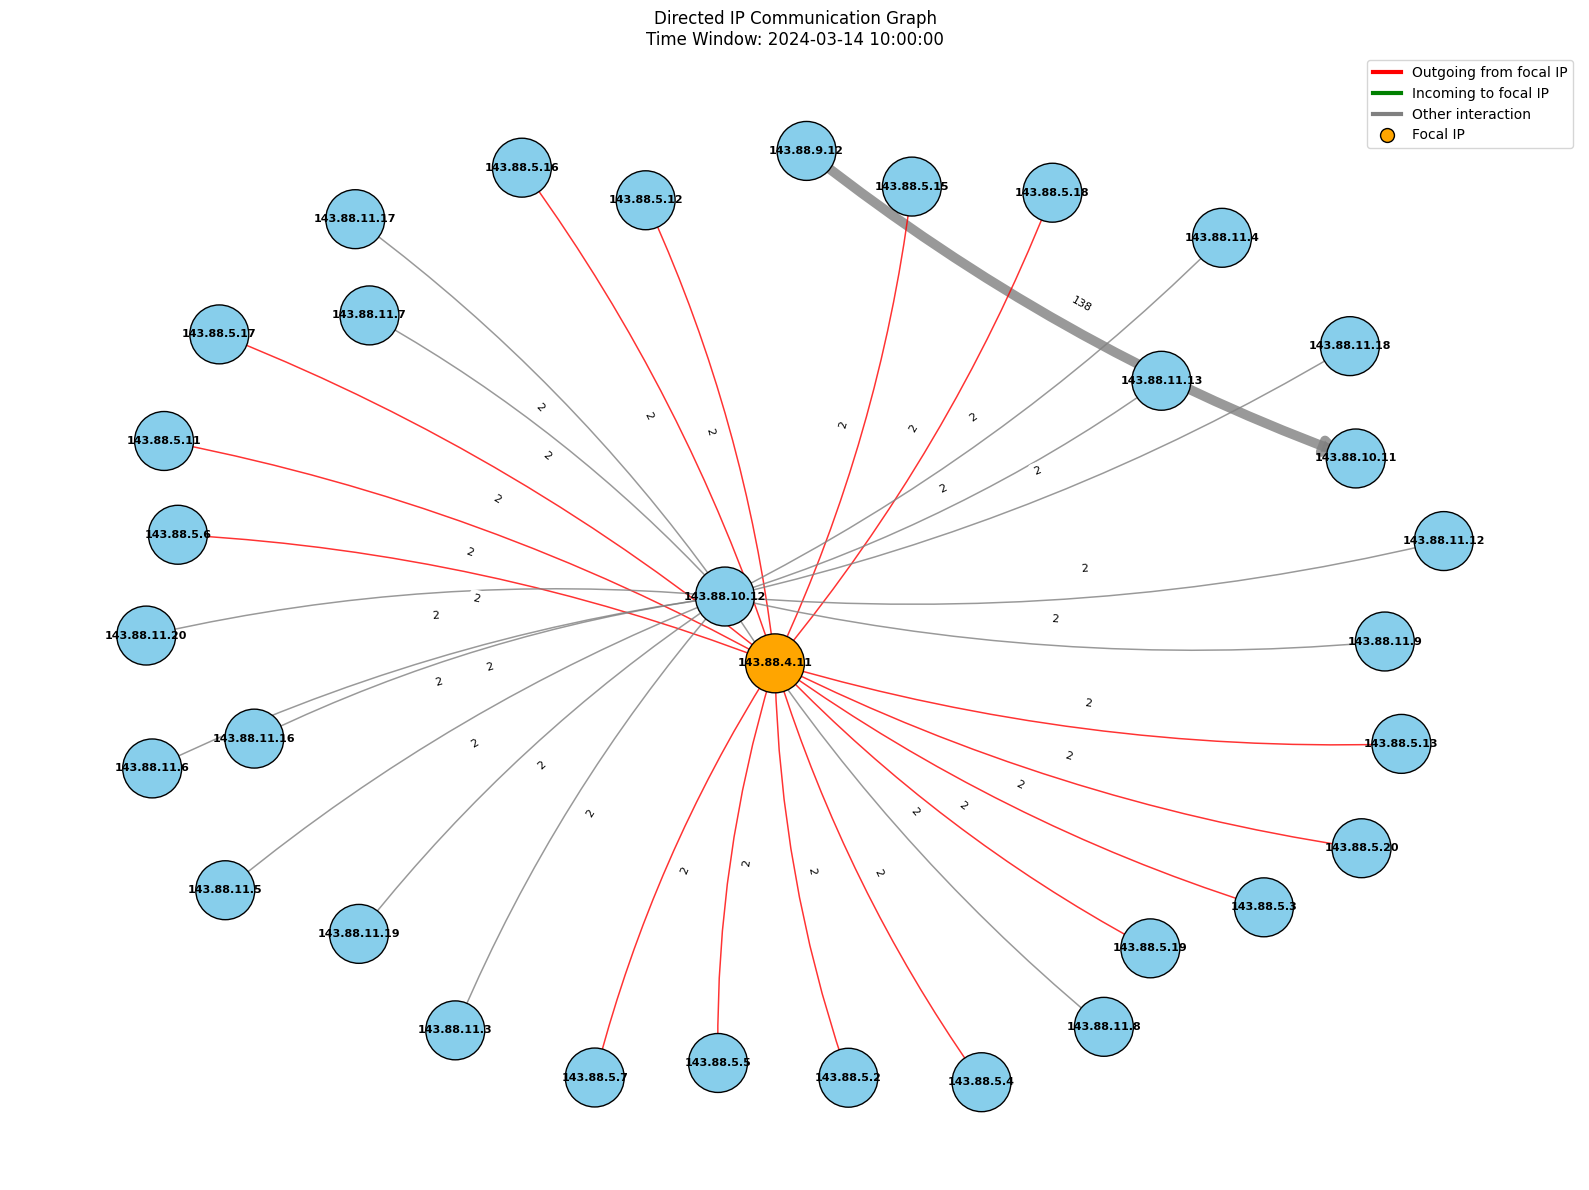

In [17]:
from matplotlib.lines import Line2D

# Create a directed graph
graph = nx.DiGraph()

for _, row in interactions.iterrows():
    graph.add_edge(
        row["src_ip_zeek"],
        row["dest_ip_zeek"],
        connection_count=row["connection_count"]
    )

# Select the most connected IP as the focal IP - IP with most number of connections in that time-window
focal_ip = max(graph.degree(), key=lambda item: item[1])[0]

print("Focal IP:", focal_ip)

# Arrange nodes
positions = nx.spring_layout(graph, seed=42, k=1.5)

maximum_count = interactions["connection_count"].max()

edge_widths = [
    1 + (graph[u][v]["connection_count"] / maximum_count) * 6
    for u, v in graph.edges()
]

# Assign colors based on direction relative to focal IP
edge_colors = []

for u, v in graph.edges():
    if u == focal_ip:
        edge_colors.append("red")       # Outgoing from focal IP
    elif v == focal_ip:
        edge_colors.append("green")     # Incoming to focal IP
    else:
        edge_colors.append("gray")      # Other interactions

plt.figure(figsize=(16, 12))

nx.draw_networkx_nodes(
    graph,
    positions,
    node_color=[
        "orange" if node == focal_ip else "skyblue"
        for node in graph.nodes()
    ],
    node_size=1800,
    edgecolors="black",
    linewidths=1
)

nx.draw_networkx_edges(
    graph,
    positions,
    width=edge_widths,
    edge_color=edge_colors,
    arrows=True,
    arrowsize=22,
    alpha=0.8,
    connectionstyle="arc3,rad=0.08"
)

nx.draw_networkx_labels(
    graph,
    positions,
    font_size=8,
    font_weight="bold"
)

edge_labels = {
    (u, v): graph[u][v]["connection_count"]
    for u, v in graph.edges()
}

nx.draw_networkx_edge_labels(
    graph,
    positions,
    edge_labels=edge_labels,
    font_size=8,
    label_pos=0.5
)

legend_items = [
    Line2D(
        [0], [0],
        color="red",
        lw=3,
        label="Outgoing from focal IP"
    ),
    Line2D(
        [0], [0],
        color="green",
        lw=3,
        label="Incoming to focal IP"
    ),
    Line2D(
        [0], [0],
        color="gray",
        lw=3,
        label="Other interaction"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor="orange",
        markeredgecolor="black",
        markersize=10,
        label="Focal IP"
    )
]

plt.legend(handles=legend_items, loc="best")

plt.title(
    f"Directed IP Communication Graph\n"
    f"Time Window: {SELECTED_WINDOW}"
)

plt.axis("off")
plt.tight_layout()
plt.show()

**UWF Zeek logs naturally represent temporal communication graphs because each event records an interaction between a source IP and destination IP. Grouping events into 5-minute windows produces graph snapshots that capture how hosts communicate and how their relationships change over time.**

## 4). Preparing 5-min edge data

##  Graph Construction from Zeek Logs

Converting raw Zeek network logs into a series of 5‑minute graph snapshots.  
Each snapshot is a directed graph where **IP addresses are nodes** and **communications are edges**.

### Nodes
- Each unique 'src_ip_zeek' or 'dest_ip_zeek' becomes a node.
- Node features summarize IP behavior in the 5‑minute window:
#### Node Features (Per IP, Per 5‑Minute Window)

Node features summarize the behavior of each IP address within a single time window.  
They are computed by aggregating all events where the IP appears as either 'src_ip_zeek' or 'dest_ip_zeek'.

##### Traffic Volume & Connectivity
- **Total outgoing connections** — count of events where IP is 'src_ip_zeek'
- **Total incoming connections** — count of events where IP is 'dest_ip_zeek'
- **Unique destinations contacted** — distinct 'dest_ip_zeek' values
- **Unique sources communicating with IP** — distinct 'src_ip_zeek' values

##### Byte & Packet Statistics
- **Total bytes sent** — sum of 'orig_bytes'
- **Total bytes received** — sum of 'resp_bytes'
- **Total packets sent** — sum of 'orig_pkts'
- **Total packets received** — sum of 'resp_pkts'
- **Total IP bytes sent** — sum of 'orig_ip_bytes'
- **Total IP bytes received** — sum of 'resp_ip_bytes'
- **Total missed bytes** — sum of 'missed_bytes'

##### Duration-Based Features
- **Average connection duration** — mean of 'duration'
- **Total connection duration** — sum of 'duration'

##### Categorical Activity Counts
- **Protocol counts** — frequency of each 'proto' (TCP, UDP, ICMP, etc.)
- **Service counts** — frequency of each 'service'
- **Connection-state counts** — frequency of each 'conn_state'

### Edges
- Each unique 'src_ip_zeek → dest_ip_zeek' pair forms a directed edge.
- Edge features capture communication behavior:
#### Edge Features (Per src_ip → dest_ip, Per 5‑Minute Window)

Edge features describe the communication behavior between a specific source IP and destination IP.

##### Traffic Volume
- **Connection count** — number of events for the pair

##### Duration Statistics
- **Total duration** — sum of 'duration'
- **Average duration** — mean of 'duration'
- **Maximum duration** — max of 'duration'

##### Byte & Packet Statistics
- **Total bytes sent** — sum of 'orig_bytes'
- **Total bytes received** — sum of 'resp_bytes'
- **Total packets sent** — sum of 'orig_pkts'
- **Total packets received** — sum of 'resp_pkts'
- **Total IP bytes sent** — sum of 'orig_ip_bytes'
- **Total IP bytes received** — sum of 'resp_ip_bytes'
- **Total missed bytes** — sum of 'missed_bytes'

##### Additional Communication Attributes
- **Destination port** — aggregated from 'dest_port_zeek'
- **Protocol counts** — frequency of each 'proto'
- **Service counts** — frequency of each 'service'
- **Connection-state counts** — frequency of each 'conn_state'

### Temporal Structure
- Logs are grouped into 5‑minute windows using 'datetime'.
- Each window becomes one graph snapshot.
- Snapshots are later split into train/validation/test sets.

### Prediction Targets (Not Used as Features)
- 'binary_target' → benign vs attack  
- 'tactic_target' → MITRE tactic  
- 'mitre_target' → MITRE technique  
- Edges may contain multiple tactics/techniques after aggregation.


In [18]:
con.execute("""
CREATE OR REPLACE TABLE edges_5min AS

SELECT
    TIME_BUCKET(INTERVAL '5 minutes', datetime) AS window_start,

    MIN(datetime) AS first_event_time,
    MAX(datetime) AS last_event_time,
    MIN(source_period) AS source_period,

    src_ip_zeek,
    dest_ip_zeek,

    -- Edge traffic features
    COUNT(*) AS connection_count,

    SUM(COALESCE(duration, 0)) AS total_duration,
    AVG(COALESCE(duration, 0)) AS average_duration,
    MAX(COALESCE(duration, 0)) AS maximum_duration,

    SUM(COALESCE(orig_bytes, 0)) AS total_orig_bytes,
    SUM(COALESCE(resp_bytes, 0)) AS total_resp_bytes,

    SUM(COALESCE(orig_pkts, 0)) AS total_orig_packets,
    SUM(COALESCE(resp_pkts, 0)) AS total_resp_packets,

    SUM(COALESCE(orig_ip_bytes, 0)) AS total_orig_ip_bytes,
    SUM(COALESCE(resp_ip_bytes, 0)) AS total_resp_ip_bytes,

    SUM(COALESCE(missed_bytes, 0)) AS total_missed_bytes,

    -- Port and protocol features
    COUNT(DISTINCT dest_port_zeek) AS unique_destination_ports,
    MODE(dest_port_zeek) AS most_common_destination_port,

    SUM(
        CASE WHEN LOWER(proto) = 'tcp' THEN 1 ELSE 0 END
    ) AS tcp_count,

    SUM(
        CASE WHEN LOWER(proto) = 'udp' THEN 1 ELSE 0 END
    ) AS udp_count,

    SUM(
        CASE WHEN LOWER(proto) = 'icmp' THEN 1 ELSE 0 END
    ) AS icmp_count,

    -- Categorical edge summaries
    MODE(service) AS most_common_service,
    MODE(conn_state) AS most_common_connection_state,

    -- Binary target
    MIN(binary_target) AS minimum_binary_target,
    MAX(binary_target) AS maximum_binary_target,
    MAX(binary_target) AS binary_target,

    -- Multi-label tactic target
    LIST(DISTINCT tactic_target ORDER BY tactic_target)
        FILTER (
            WHERE binary_target = 1
              AND tactic_target IS NOT NULL
        ) AS tactic_targets,

    -- Multi-label MITRE technique target
    LIST(DISTINCT mitre_target ORDER BY mitre_target)
        FILTER (
            WHERE binary_target = 1
              AND mitre_target IS NOT NULL
        ) AS mitre_targets,

    COUNT(DISTINCT tactic_target)
        FILTER (
            WHERE binary_target = 1
              AND tactic_target IS NOT NULL
        ) AS tactic_count,

    COUNT(DISTINCT mitre_target)
        FILTER (
            WHERE binary_target = 1
              AND mitre_target IS NOT NULL
        ) AS mitre_count

FROM cleaned_logs

GROUP BY
    window_start,
    src_ip_zeek,
    dest_ip_zeek;
""")

print("Created table: edges_5min")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Created table: edges_5min


In [19]:
## saving the edge table

EDGE_FILE = "edges_5min.parquet"

con.execute(f"""
COPY edges_5min
TO '{EDGE_FILE}'
(
    FORMAT PARQUET,
    COMPRESSION ZSTD
);
""")

print(f"Saved edge data to: {EDGE_FILE}")

Saved edge data to: edges_5min.parquet


In [20]:
## reloading the file

# con.execute("""
# CREATE OR REPLACE VIEW edges_5min AS
# SELECT *
# FROM read_parquet('edges_5min.parquet');
# """)

In [21]:
SOURCE_OBJECT = "edges_5min"

row_count = con.execute(f"""
    SELECT COUNT(*)
    FROM {SOURCE_OBJECT};
""").fetchone()[0]

column_info = con.execute(f"""
    DESCRIBE {SOURCE_OBJECT};
""").fetchall()

column_count = len(column_info)

print("Rows:", f"{row_count:,}")
print("Columns:", column_count)
print("Estimated shape:", (row_count, column_count))

print("\nColumns:")
for column in column_info:
    print(f"- {column[0]}: {column[1]}")

Rows: 678,054
Columns: 31
Estimated shape: (678054, 31)

Columns:
- window_start: TIMESTAMP
- first_event_time: TIMESTAMP_NS
- last_event_time: TIMESTAMP_NS
- source_period: VARCHAR
- src_ip_zeek: VARCHAR
- dest_ip_zeek: VARCHAR
- connection_count: BIGINT
- total_duration: DOUBLE
- average_duration: DOUBLE
- maximum_duration: DOUBLE
- total_orig_bytes: DOUBLE
- total_resp_bytes: DOUBLE
- total_orig_packets: HUGEINT
- total_resp_packets: HUGEINT
- total_orig_ip_bytes: HUGEINT
- total_resp_ip_bytes: HUGEINT
- total_missed_bytes: HUGEINT
- unique_destination_ports: BIGINT
- most_common_destination_port: INTEGER
- tcp_count: HUGEINT
- udp_count: HUGEINT
- icmp_count: HUGEINT
- most_common_service: VARCHAR
- most_common_connection_state: VARCHAR
- minimum_binary_target: INTEGER
- maximum_binary_target: INTEGER
- binary_target: INTEGER
- tactic_targets: VARCHAR[]
- mitre_targets: VARCHAR[]
- tactic_count: BIGINT
- mitre_count: BIGINT


In [22]:
## Loading the data as pandas dataframe for further preparation

edges_df = con.execute("""
    SELECT *
    FROM edges_5min;
""").df()

In [23]:
edges_df.shape

(678054, 31)

In [24]:
edges_df.head()

,window_start,first_event_time,last_event_time,source_period,src_ip_zeek,dest_ip_zeek,connection_count,total_duration,average_duration,maximum_duration,...,icmp_count,most_common_service,most_common_connection_state,minimum_binary_target,maximum_binary_target,binary_target,tactic_targets,mitre_targets,tactic_count,mitre_count
0,2021-12-17 14:45:00,2021-12-17 14:46:52.434,2021-12-17 14:49:00.744,2021-12-12%20-%202021-12-19,fe80::250:56ff:fe9e:5457,ff02::1:2,5,0.0,0.0,0.0,...,0.0,NaN,S0,0,0,0,<NA>,<NA>,0,0
1,2021-12-17 14:50:00,2021-12-17 14:53:53.026,2021-12-17 14:53:53.027,2021-12-12%20-%202021-12-19,fe80::250:56ff:fe9e:f1c3,2001:500:a8::e,4,0.0,0.0,0.0,...,0.0,dns,S0,0,0,0,<NA>,<NA>,0,0
2,2021-12-17 15:05:00,2021-12-17 15:09:08.164,2021-12-17 15:09:08.164,2021-12-12%20-%202021-12-19,172.28.128.3,224.0.0.251,2,0.0,0.0,0.0,...,0.0,dns,S0,0,0,0,<NA>,<NA>,0,0
3,2021-12-17 15:35:00,2021-12-17 15:36:57.649,2021-12-17 15:36:57.649,2021-12-12%20-%202021-12-19,143.88.0.2,202.12.27.33,2,0.0,0.0,0.0,...,0.0,dns,S0,0,0,0,<NA>,<NA>,0,0
4,2021-12-17 15:40:00,2021-12-17 15:40:02.733,2021-12-17 15:40:02.733,2021-12-12%20-%202021-12-19,143.88.0.2,193.0.14.129,2,0.0,0.0,0.0,...,0.0,dns,S0,0,0,0,<NA>,<NA>,0,0


In [25]:
edges_df.tail()

,window_start,first_event_time,last_event_time,source_period,src_ip_zeek,dest_ip_zeek,connection_count,total_duration,average_duration,maximum_duration,...,icmp_count,most_common_service,most_common_connection_state,minimum_binary_target,maximum_binary_target,binary_target,tactic_targets,mitre_targets,tactic_count,mitre_count
678049,2025-05-25 16:30:00,2025-05-25 16:33:22.207878,2025-05-25 16:33:22.207878,2025-05-25%20-%202025-06-01,143.88.0.9,143.88.0.10,1,18.298992,18.298992,18.298992,...,1.0,NaN,OTH,0,0,0,<NA>,<NA>,0,0
678050,2025-05-25 16:40:00,2025-05-25 16:42:49.931346,2025-05-25 16:42:49.931346,2025-05-25%20-%202025-06-01,143.88.4.13,143.88.4.255,1,0.000000,0.000000,0.000000,...,0.0,NaN,S0,0,0,0,<NA>,<NA>,0,0
678051,2025-05-27 10:25:00,2025-05-27 10:26:30.503496,2025-05-27 10:26:30.503496,2025-05-25%20-%202025-06-01,143.88.0.5,143.88.0.6,1,15.930990,15.930990,15.930990,...,1.0,NaN,OTH,0,0,0,<NA>,<NA>,0,0
678052,2025-05-26 08:30:00,2025-05-26 08:31:03.176749,2025-05-26 08:31:03.176749,2025-05-25%20-%202025-06-01,143.88.0.10,198.97.190.53,1,0.000000,0.000000,0.000000,...,0.0,dns,S0,0,0,0,<NA>,<NA>,0,0
678053,2025-05-25 08:15:00,2025-05-25 08:19:07.080589,2025-05-25 08:19:07.080589,2025-05-25%20-%202025-06-01,143.88.0.9,143.88.0.10,1,18.261494,18.261494,18.261494,...,1.0,NaN,OTH,0,0,0,<NA>,<NA>,0,0


In [26]:
edges_df.isnull().sum()

window_start                         0
first_event_time                     0
last_event_time                      0
source_period                        0
src_ip_zeek                          0
dest_ip_zeek                         0
connection_count                     0
total_duration                       0
average_duration                     0
maximum_duration                     0
total_orig_bytes                     0
total_resp_bytes                     0
total_orig_packets                   0
total_resp_packets                   0
total_orig_ip_bytes                  0
total_resp_ip_bytes                  0
total_missed_bytes                   0
unique_destination_ports             0
most_common_destination_port         0
tcp_count                            0
udp_count                            0
icmp_count                           0
most_common_service             105949
most_common_connection_state         0
minimum_binary_target                0
maximum_binary_target    

In [27]:
## validating targets alignment

alignment_check = con.execute("""
    SELECT
        COUNT(*) AS total_edges,

        COUNT(*) FILTER (
            WHERE minimum_binary_target != maximum_binary_target
        ) AS mixed_binary_edges,

        COUNT(*) FILTER (
            WHERE binary_target NOT IN (0, 1)
        ) AS invalid_binary_targets,

        COUNT(*) FILTER (
            WHERE binary_target = 0
              AND tactic_targets IS NOT NULL
        ) AS benign_edges_with_tactic,

        COUNT(*) FILTER (
            WHERE binary_target = 0
              AND mitre_targets IS NOT NULL
        ) AS benign_edges_with_mitre,

        COUNT(*) FILTER (
            WHERE binary_target = 1
              AND tactic_targets IS NULL
        ) AS attack_edges_without_tactic,

        COUNT(*) FILTER (
            WHERE binary_target = 1
              AND mitre_targets IS NULL
        ) AS attack_edges_without_mitre,

        COUNT(*) FILTER (
            WHERE COALESCE(LEN(tactic_targets), 0) != tactic_count
        ) AS tactic_count_mismatches,

        COUNT(*) FILTER (
            WHERE COALESCE(LEN(mitre_targets), 0) != mitre_count
        ) AS mitre_count_mismatches

    FROM edges_5min;
""").fetchone()

column_names = [
    "total_edges",
    "mixed_binary_edges",
    "invalid_binary_targets",
    "benign_edges_with_tactic",
    "benign_edges_with_mitre",
    "attack_edges_without_tactic",
    "attack_edges_without_mitre",
    "tactic_count_mismatches",
    "mitre_count_mismatches"
]

for name, value in zip(column_names, alignment_check):
    print(f"{name}: {value}")

total_edges: 678054
mixed_binary_edges: 0
invalid_binary_targets: 0
benign_edges_with_tactic: 0
benign_edges_with_mitre: 0
attack_edges_without_tactic: 0
attack_edges_without_mitre: 340
tactic_count_mismatches: 0
mitre_count_mismatches: 0


In [28]:
## handling missing values

# Replace missing service values with an explicit category
edges_df["most_common_service"] = (
    edges_df["most_common_service"]
    .fillna("unknown")
)

# Convert missing target lists into empty lists
def ensure_list(value):
    if value is None:
        return []

    try:
        if pd.isna(value):
            return []
    except (TypeError, ValueError):
        pass

    return list(value)

edges_df["tactic_targets"] = (
    edges_df["tactic_targets"]
    .apply(ensure_list)
)

edges_df["mitre_targets"] = (
    edges_df["mitre_targets"]
    .apply(ensure_list)
)

# Flags for task-specific supervision
edges_df["has_tactic_target"] = (
    edges_df["tactic_count"] > 0
)

edges_df["has_mitre_target"] = (
    edges_df["mitre_count"] > 0
)

print("Missing-value handling completed.")
print("Edges with MITRE supervision:",
      edges_df["has_mitre_target"].sum())

Missing-value handling completed.
Edges with MITRE supervision: 54310


service → "unknown"

missing tactic list → []

missing MITRE list → []

The missing MITRE and Tactic is replaced by empty list []

In [29]:
edges_df.isnull().sum()

window_start                    0
first_event_time                0
last_event_time                 0
source_period                   0
src_ip_zeek                     0
dest_ip_zeek                    0
connection_count                0
total_duration                  0
average_duration                0
maximum_duration                0
total_orig_bytes                0
total_resp_bytes                0
total_orig_packets              0
total_resp_packets              0
total_orig_ip_bytes             0
total_resp_ip_bytes             0
total_missed_bytes              0
unique_destination_ports        0
most_common_destination_port    0
tcp_count                       0
udp_count                       0
icmp_count                      0
most_common_service             0
most_common_connection_state    0
minimum_binary_target           0
maximum_binary_target           0
binary_target                   0
tactic_targets                  0
mitre_targets                   0
tactic_count  

In [30]:
edges_df.loc[edges_df["window_start"] == "2021-12-18 01:00:00"]

,window_start,first_event_time,last_event_time,source_period,src_ip_zeek,dest_ip_zeek,connection_count,total_duration,average_duration,maximum_duration,...,most_common_connection_state,minimum_binary_target,maximum_binary_target,binary_target,tactic_targets,mitre_targets,tactic_count,mitre_count,has_tactic_target,has_mitre_target
6323,2021-12-18 01:00:00,2021-12-18 01:00:20.022000,2021-12-18 01:04:57.453000,2021-12-12%20-%202021-12-19,143.88.1.53,143.88.1.1,23,0.010881,0.000473,0.000814,...,SF,0,0,0,[],[],0,0,False,False
7607,2021-12-18 01:00:00,2021-12-18 01:04:39.647000,2021-12-18 01:04:39.647000,2021-12-12%20-%202021-12-19,143.88.0.2,192.112.36.4,2,0.000000,0.000000,0.000000,...,S0,0,0,0,[],[],0,0,False,False
50106,2021-12-18 01:00:00,2021-12-18 01:01:26.370000,2021-12-18 01:01:26.370000,2021-12-12%20-%202021-12-19,fe80::250:56ff:fe9e:2553,ff02::2,2,0.000000,0.000000,0.000000,...,OTH,0,0,0,[],[],0,0,False,False
80651,2021-12-18 01:00:00,2021-12-18 01:00:48.811000,2021-12-18 01:00:49.575202,2021-12-12%20-%202021-12-19,fe80::cc00:7eec:36b8:5325,ff02::16,3,14.659618,4.886539,5.140976,...,OTH,0,0,0,[],[],0,0,False,False
156236,2021-12-18 01:00:00,2021-12-18 01:00:48.819000,2021-12-18 01:00:53.840000,2021-12-12%20-%202021-12-19,fe80::70d8:2461:35d9:c9ea,ff02::1:3,4,0.412679,0.103170,0.109618,...,S0,0,0,0,[],[],0,0,False,False
156237,2021-12-18 01:00:00,2021-12-18 01:04:27.746000,2021-12-18 01:04:27.746000,2021-12-12%20-%202021-12-19,143.88.0.2,192.58.128.30,2,0.000000,0.000000,0.000000,...,S0,0,0,0,[],[],0,0,False,False
186553,2021-12-18 01:00:00,2021-12-18 01:01:12.158778,2021-12-18 01:01:12.267000,2021-12-12%20-%202021-12-19,143.88.1.53,224.0.0.251,3,0.000000,0.000000,0.000000,...,S0,0,0,0,[],[],0,0,False,False
250309,2021-12-18 01:00:00,2021-12-18 01:00:51.944000,2021-12-18 01:04:58.597573,2021-12-12%20-%202021-12-19,fe80::70d8:2461:35d9:c9ea,ff02::1:2,3,189.152053,63.050684,63.050858,...,S0,0,0,0,[],[],0,0,False,False
272445,2021-12-18 01:00:00,2021-12-18 01:00:18.855000,2021-12-18 01:04:18.915000,2021-12-12%20-%202021-12-19,fe80::250:56ff:fe9e:5457,ff02::1:2,6,0.000000,0.000000,0.000000,...,S0,0,0,0,[],[],0,0,False,False
283025,2021-12-18 01:00:00,2021-12-18 01:00:00.528000,2021-12-18 01:02:44.072000,2021-12-12%20-%202021-12-19,172.28.128.3,172.28.128.255,6,22.849432,3.808239,7.421541,...,S0,0,0,0,[],[],0,0,False,False


In [31]:
edges_df["binary_target"].value_counts()

binary_target
0    623404
1     54650
Name: count, dtype: int64

In [32]:
edges_df["mitre_targets"].value_counts()

mitre_targets
[]                              623744
[T1595]                          37156
[T1078]                           4869
[T1110]                           4759
[T1190]                           4284
[T1046]                            569
[T1018]                            527
[T1078, T1110]                     409
[T1048, T1078]                     337
[T1190, T1595]                     307
[T1590, T1592]                     281
[T1548]                            273
[T1078, T1595]                     135
[T1048, T1078, T1595]              111
[T1110, T1595]                      78
[T1048, T1078, T1110]               37
[T1589]                             29
[T1587]                             22
[T1210]                             19
[T1589, T1590, T1592]               19
[T1016]                             15
[T1078, T1110, T1595]               13
[T1203, T1587]                      10
[T1048, T1078, T1110, T1595]         9
[T1590]                              6
[T1071]    

In [33]:
edges_df["tactic_targets"].value_counts()

tactic_targets
[]                                                                      623404
[Reconnaissance]                                                         37810
[Defense Evasion]                                                         5143
[Credential Access]                                                       4770
[Initial Access]                                                          4285
[Discovery]                                                               1118
[Credential Access, Defense Evasion]                                       409
[Defense Evasion, Exfiltration]                                            337
[Initial Access, Reconnaissance]                                           307
[Defense Evasion, Reconnaissance]                                          135
[Defense Evasion, Exfiltration, Reconnaissance]                            111
[Credential Access, Reconnaissance]                                         78
[Credential Access, Defense Evasion, 

In [34]:
edges_df.columns

Index(['window_start', 'first_event_time', 'last_event_time', 'source_period',
       'src_ip_zeek', 'dest_ip_zeek', 'connection_count', 'total_duration',
       'average_duration', 'maximum_duration', 'total_orig_bytes',
       'total_resp_bytes', 'total_orig_packets', 'total_resp_packets',
       'total_orig_ip_bytes', 'total_resp_ip_bytes', 'total_missed_bytes',
       'unique_destination_ports', 'most_common_destination_port', 'tcp_count',
       'udp_count', 'icmp_count', 'most_common_service',
       'most_common_connection_state', 'minimum_binary_target',
       'maximum_binary_target', 'binary_target', 'tactic_targets',
       'mitre_targets', 'tactic_count', 'mitre_count', 'has_tactic_target',
       'has_mitre_target'],
      dtype='str')

**has_mitre_target has info about the edges that had MITRE target missing.**

## 5). Train-Validation-Split 

**Using chronological ordering - 70% train, 15% val, 15% test**

In [35]:

# # Get unique windows and order them from oldest to newest
# unique_windows = (
#     edges_df["window_start"]
#     .dropna()
#     .drop_duplicates()
#     .sort_values()
#     .reset_index(drop=True)
# )

# total_windows = len(unique_windows)

# # Split by graph windows
# train_end = int(total_windows * 0.70)
# validation_end = int(total_windows * 0.85)

# train_windows = set(unique_windows.iloc[:train_end])
# validation_windows = set(
#     unique_windows.iloc[train_end:validation_end]
# )
# test_windows = set(unique_windows.iloc[validation_end:])

# # Assign each edge based on its 5-minute window
# edges_df["data_split"] = "test"

# edges_df.loc[
#     edges_df["window_start"].isin(train_windows),
#     "data_split"
# ] = "train"

# edges_df.loc[
#     edges_df["window_start"].isin(validation_windows),
#     "data_split"
# ] = "validation"

# # Display split summary
# split_summary = (
#     edges_df
#     .groupby("data_split")
#     .agg(
#         edge_count=("window_start", "size"),
#         window_count=("window_start", "nunique"),
#         earliest_window=("window_start", "min"),
#         latest_window=("window_start", "max")
#     )
#     .reindex(["train", "validation", "test"])
# )

# display(split_summary)

In [36]:
# train_df = edges_df[edges_df["data_split"] == "train"].sample(
#     frac=1,
#     random_state=42
# )

# validation_df = edges_df[
#     edges_df["data_split"] == "validation"
# ]

# test_df = edges_df[
#     edges_df["data_split"] == "test"
# ]

In [37]:
# train_df["binary_target"].value_counts()

In [38]:
# validation_df["binary_target"].value_counts()

In [39]:
# test_df["binary_target"].value_counts()

**There are no attack samples in validation with this split**

#### 80-10-10 split

In [40]:
# # Sort all unique 5-minute windows chronologically
# unique_windows = (
#     edges_df["window_start"]
#     .dropna()
#     .drop_duplicates()
#     .sort_values()
#     .reset_index(drop=True)
# )

# total_windows = len(unique_windows)

# train_end = int(total_windows * 0.80)
# validation_end = int(total_windows * 0.90)

# train_windows = set(unique_windows.iloc[:train_end])
# validation_windows = set(
#     unique_windows.iloc[train_end:validation_end]
# )
# test_windows = set(unique_windows.iloc[validation_end:])

# candidate_df = edges_df.copy()

# candidate_df["candidate_split"] = "test"

# candidate_df.loc[
#     candidate_df["window_start"].isin(train_windows),
#     "candidate_split"
# ] = "train"

# candidate_df.loc[
#     candidate_df["window_start"].isin(validation_windows),
#     "candidate_split"
# ] = "validation"

# candidate_summary = (
#     candidate_df
#     .groupby("candidate_split")
#     .agg(
#         edge_count=("binary_target", "size"),
#         benign_edges=("binary_target", lambda x: (x == 0).sum()),
#         attack_edges=("binary_target", lambda x: (x == 1).sum()),
#         earliest_window=("window_start", "min"),
#         latest_window=("window_start", "max")
#     )
#     .reindex(["train", "validation", "test"])
# )

# display(candidate_summary)

**with 80-10-10 split there are only 9 edges with attack in validation**

### Inspecting attack distribution over time

In [41]:
monthly_distribution = (
    edges_df
    .assign(
        year=edges_df["window_start"].dt.year,
        month=edges_df["window_start"].dt.month
    )
    .groupby(["year", "month"])
    .agg(
        total_edges=("binary_target", "size"),
        benign_edges=("binary_target", lambda x: (x == 0).sum()),
        attack_edges=("binary_target", lambda x: (x == 1).sum())
    )
    .reset_index()
)

monthly_distribution["attack_percentage"] = (
    100 * monthly_distribution["attack_edges"]
    / monthly_distribution["total_edges"]
)

display(monthly_distribution)

,year,month,total_edges,benign_edges,attack_edges,attack_percentage
0,2021,12,64450,64450,0,0.000000
1,2022,1,85685,85685,0,0.000000
2,2022,2,340,0,340,100.000000
3,2022,8,48,0,48,100.000000
4,2022,9,364,0,364,100.000000
5,2022,10,27,0,27,100.000000
6,2024,2,5369,0,5369,100.000000
7,2024,3,46402,0,46402,100.000000
8,2024,9,65,0,65,100.000000
9,2024,10,7088,7064,24,0.338600


**The attacks happened only during specific times of the year**

**Below two are the only options**

- Stratified window split: fair comparison of GNN models under similar distributions.

- Chronological holdout: robustness to future data and distribution shift.

#### 5.1 Stratified random graph-window split

**This keeps similar attack proportions in all splits. Windows from different years may appear in every split.**

In [42]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Create one label for each 5-minute graph window
window_labels = (
    edges_df
    .groupby("window_start")
    .agg(
        window_attack_label=("binary_target", "max")
    )
    .reset_index()
)

# 80% training, 20% temporary set
train_windows, temporary_windows = train_test_split(
    window_labels,
    test_size=0.20,
    random_state=42,
    stratify=window_labels["window_attack_label"]
)

# Split temporary set equally into validation and test
validation_windows, test_windows = train_test_split(
    temporary_windows,
    test_size=0.50,
    random_state=42,
    stratify=temporary_windows["window_attack_label"]
)

# Create window-to-split mapping
window_split_map = {}

for window in train_windows["window_start"]:
    window_split_map[window] = "train"

for window in validation_windows["window_start"]:
    window_split_map[window] = "validation"

for window in test_windows["window_start"]:
    window_split_map[window] = "test"

# Assign every edge according to its complete graph window
edges_stratified_df = edges_df.copy()

edges_stratified_df["data_split"] = (
    edges_stratified_df["window_start"]
    .map(window_split_map)
)

# Verify
stratified_summary = (
    edges_stratified_df
    .groupby("data_split")
    .agg(
        edge_count=("binary_target", "size"),
        window_count=("window_start", "nunique"),
        benign_edges=("binary_target", lambda x: (x == 0).sum()),
        attack_edges=("binary_target", lambda x: (x == 1).sum()),
        earliest_window=("window_start", "min"),
        latest_window=("window_start", "max")
    )
    .reindex(["train", "validation", "test"])
)

display(stratified_summary)

,edge_count,window_count,benign_edges,attack_edges,earliest_window,latest_window
data_split,,,,,,
train,541762,20148,498396,43366,2021-12-17 07:00:00,2025-07-31 14:55:00
validation,67130,2519,61517,5613,2021-12-17 07:45:00,2025-07-25 21:20:00
test,69162,2519,63491,5671,2021-12-17 09:05:00,2025-07-25 18:40:00


In [43]:
import pandas as pd

def check_label_coverage(df, target_column):
    exploded = (
        df[["data_split", target_column]]
        .explode(target_column)
        .rename(columns={target_column: "label"})
    )

    exploded = exploded.dropna(subset=["label"])

    summary = (
        exploded
        .groupby("data_split")
        .agg(
            unique_labels=("label", "nunique"),
            labeled_edges=("label", "size")
        )
        .reindex(["train", "validation", "test"])
    )

    labels_by_split = {
        split: set(
            exploded.loc[
                exploded["data_split"] == split,
                "label"
            ]
        )
        for split in ["train", "validation", "test"]
    }

    train_labels = labels_by_split["train"]

    unseen_validation = (
        labels_by_split["validation"] - train_labels
    )

    unseen_test = (
        labels_by_split["test"] - train_labels
    )

    return summary, unseen_validation, unseen_test


tactic_summary, unseen_tactics_validation, unseen_tactics_test = (
    check_label_coverage(
        edges_stratified_df,
        "tactic_targets"
    )
)

technique_summary, unseen_techniques_validation, unseen_techniques_test = (
    check_label_coverage(
        edges_stratified_df,
        "mitre_targets"
    )
)

print("TACTIC COVERAGE")
display(tactic_summary)

print("Tactics unseen during training but present in validation:")
print(sorted(unseen_tactics_validation))

print("Tactics unseen during training but present in testing:")
print(sorted(unseen_tactics_test))

print("\nMITRE TECHNIQUE COVERAGE")
display(technique_summary)

print("Techniques unseen during training but present in validation:")
print(sorted(unseen_techniques_validation))

print("Techniques unseen during training but present in testing:")
print(sorted(unseen_techniques_test))

TACTIC COVERAGE


,unique_labels,labeled_edges
data_split,,
train,12,44661
validation,9,5792
test,11,5838


Tactics unseen during training but present in validation:
[]
Tactics unseen during training but present in testing:
['Collection']

MITRE TECHNIQUE COVERAGE


,unique_labels,labeled_edges
data_split,,
train,26,44849
validation,11,5820
test,17,5602


Techniques unseen during training but present in validation:
[]
Techniques unseen during training but present in testing:
['T1557']


**The initial data split used only the binary attack label, which caused some MITRE tactics and techniques to appear in validation or testing but not in training. This meant the model would be asked to predict classes it had never seen.**

**The fix was to identify those missing tactics/techniques, find the 5‑minute windows containing them, and move those entire windows into the training set. After doing this, all tactics and techniques in validation and testing were also present in training, creating a proper closed‑set classification setup.**

In [44]:
def labels_in_split(df, split_name, column_name):
    labels = set()

    values = df.loc[
        df["data_split"] == split_name,
        column_name
    ]

    for value in values:
        if isinstance(value, (list, tuple, set)):
            labels.update(value)

    return labels


def windows_containing_label(df, column_name, label):
    return set(
        df.loc[
            df[column_name].apply(
                lambda values: (
                    isinstance(values, (list, tuple, set))
                    and label in values
                )
            ),
            "window_start"
        ]
    )


# Find labels currently missing from the training split
train_tactics = labels_in_split(
    edges_stratified_df,
    "train",
    "tactic_targets"
)

validation_tactics = labels_in_split(
    edges_stratified_df,
    "validation",
    "tactic_targets"
)

test_tactics = labels_in_split(
    edges_stratified_df,
    "test",
    "tactic_targets"
)

missing_tactics = (
    validation_tactics | test_tactics
) - train_tactics


train_techniques = labels_in_split(
    edges_stratified_df,
    "train",
    "mitre_targets"
)

validation_techniques = labels_in_split(
    edges_stratified_df,
    "validation",
    "mitre_targets"
)

test_techniques = labels_in_split(
    edges_stratified_df,
    "test",
    "mitre_targets"
)

missing_techniques = (
    validation_techniques | test_techniques
) - train_techniques


# Find complete windows containing missing labels
windows_to_move = set()

for label in missing_tactics:
    windows_to_move.update(
        windows_containing_label(
            edges_stratified_df,
            "tactic_targets",
            label
        )
    )

for label in missing_techniques:
    windows_to_move.update(
        windows_containing_label(
            edges_stratified_df,
            "mitre_targets",
            label
        )
    )


# Move complete graph windows into training
edges_stratified_df.loc[
    edges_stratified_df["window_start"].isin(windows_to_move),
    "data_split"
] = "train"

print("Moved windows to training:", len(windows_to_move))
print("Tactics previously missing:", sorted(missing_tactics))
print("Techniques previously missing:", sorted(missing_techniques))

Moved windows to training: 1
Tactics previously missing: ['Collection']
Techniques previously missing: ['T1557']


In [45]:
import pandas as pd

def check_label_coverage(df, target_column):
    exploded = (
        df[["data_split", target_column]]
        .explode(target_column)
        .rename(columns={target_column: "label"})
    )

    exploded = exploded.dropna(subset=["label"])

    summary = (
        exploded
        .groupby("data_split")
        .agg(
            unique_labels=("label", "nunique"),
            labeled_edges=("label", "size")
        )
        .reindex(["train", "validation", "test"])
    )

    labels_by_split = {
        split: set(
            exploded.loc[
                exploded["data_split"] == split,
                "label"
            ]
        )
        for split in ["train", "validation", "test"]
    }

    train_labels = labels_by_split["train"]

    unseen_validation = (
        labels_by_split["validation"] - train_labels
    )

    unseen_test = (
        labels_by_split["test"] - train_labels
    )

    return summary, unseen_validation, unseen_test


tactic_summary, unseen_tactics_validation, unseen_tactics_test = (
    check_label_coverage(
        edges_stratified_df,
        "tactic_targets"
    )
)

technique_summary, unseen_techniques_validation, unseen_techniques_test = (
    check_label_coverage(
        edges_stratified_df,
        "mitre_targets"
    )
)

print("TACTIC COVERAGE")
display(tactic_summary)

print("Tactics unseen during training but present in validation:")
print(sorted(unseen_tactics_validation))

print("Tactics unseen during training but present in testing:")
print(sorted(unseen_tactics_test))

print("\nMITRE TECHNIQUE COVERAGE")
display(technique_summary)

print("Techniques unseen during training but present in validation:")
print(sorted(unseen_techniques_validation))

print("Techniques unseen during training but present in testing:")
print(sorted(unseen_techniques_test))

TACTIC COVERAGE


,unique_labels,labeled_edges
data_split,,
train,13,44662
validation,9,5792
test,10,5837


Tactics unseen during training but present in validation:
[]
Tactics unseen during training but present in testing:
[]

MITRE TECHNIQUE COVERAGE


,unique_labels,labeled_edges
data_split,,
train,27,44850
validation,11,5820
test,16,5601


Techniques unseen during training but present in validation:
[]
Techniques unseen during training but present in testing:
[]


In [46]:
train_df = edges_stratified_df[edges_stratified_df["data_split"] == "train"].sample(
    frac=1,
    random_state=42
)

validation_df = edges_stratified_df[
    edges_stratified_df["data_split"] == "validation"
]

test_df = edges_stratified_df[
    edges_stratified_df["data_split"] == "test"
]

In [47]:
# ## saving the splits

# import os

# OUTPUT_DIR = "processed_edges"
# os.makedirs(OUTPUT_DIR, exist_ok=True)

# train_df.to_parquet(
#     f"{OUTPUT_DIR}/train_edges.parquet",
#     index=False
# )

# validation_df.to_parquet(
#     f"{OUTPUT_DIR}/validation_edges.parquet",
#     index=False
# )

# test_df.to_parquet(
#     f"{OUTPUT_DIR}/test_edges.parquet",
#     index=False
# )

# print("Saved:")
# print(f"- {OUTPUT_DIR}/train_edges.parquet")
# print(f"- {OUTPUT_DIR}/validation_edges.parquet")
# print(f"- {OUTPUT_DIR}/test_edges.parquet")

## 6). Defining model input features

In [48]:
train_df.columns

Index(['window_start', 'first_event_time', 'last_event_time', 'source_period',
       'src_ip_zeek', 'dest_ip_zeek', 'connection_count', 'total_duration',
       'average_duration', 'maximum_duration', 'total_orig_bytes',
       'total_resp_bytes', 'total_orig_packets', 'total_resp_packets',
       'total_orig_ip_bytes', 'total_resp_ip_bytes', 'total_missed_bytes',
       'unique_destination_ports', 'most_common_destination_port', 'tcp_count',
       'udp_count', 'icmp_count', 'most_common_service',
       'most_common_connection_state', 'minimum_binary_target',
       'maximum_binary_target', 'binary_target', 'tactic_targets',
       'mitre_targets', 'tactic_count', 'mitre_count', 'has_tactic_target',
       'has_mitre_target', 'data_split'],
      dtype='str')

In [49]:
len(train_df.columns)

34

In [50]:
numeric_edge_features = [
    "connection_count",
    "total_duration",
    "average_duration",
    "maximum_duration",
    "total_orig_bytes",
    "total_resp_bytes",
    "total_orig_packets",
    "total_resp_packets",
    "total_orig_ip_bytes",
    "total_resp_ip_bytes",
    "total_missed_bytes",
    "unique_destination_ports",
    "most_common_destination_port",
    "tcp_count",
    "udp_count",
    "icmp_count"
]

categorical_edge_features = [
    "most_common_service",
    "most_common_connection_state"
]

target_columns = [
    "binary_target",
    "tactic_targets",
    "mitre_targets"
]

metadata_columns = [
    "window_start",
    "first_event_time",
    "last_event_time",
    "source_period",
    "src_ip_zeek",
    "dest_ip_zeek",
    "data_split"
]

all_required_columns = (
    numeric_edge_features
    + categorical_edge_features
    + target_columns
    + metadata_columns
)

for column in all_required_columns:
    if column not in train_df.columns:
        print(f"Missing column: {column}")

print("Numeric edge features:", len(numeric_edge_features))
print("Categorical edge features:", len(categorical_edge_features))
print("Target columns:", target_columns)
print("Feature columns verified.")

Numeric edge features: 16
Categorical edge features: 2
Target columns: ['binary_target', 'tactic_targets', 'mitre_targets']
Feature columns verified.


## 7). Applying Log Transformation to Numeric features

log1p - to correct skewness and handle large values

In [51]:
import numpy as np

log_features = [
    "connection_count",
    "total_duration",
    "average_duration",
    "maximum_duration",
    "total_orig_bytes",
    "total_resp_bytes",
    "total_orig_packets",
    "total_resp_packets",
    "total_orig_ip_bytes",
    "total_resp_ip_bytes",
    "total_missed_bytes",
    "unique_destination_ports",
    "tcp_count",
    "udp_count",
    "icmp_count"
]

dataframes = {
    "train": train_df,
    "validation": validation_df,
    "test": test_df
}

# Confirm that these features do not contain negative values
for split_name, df in dataframes.items():
    for column in log_features:
        negative_count = (df[column] < 0).sum()

        if negative_count > 0:
            print(
                f"{split_name} - {column}: "
                f"{negative_count} negative values"
            )

# Apply log1p consistently to all splits
for df in dataframes.values():
    for column in log_features:
        df[column] = np.log1p(
            df[column].astype("float64")
        )

print("Applied log1p transformation to numeric traffic features.")

Applied log1p transformation to numeric traffic features.


## 8). Computing Node Features from edges_stratified_df

In [52]:
import pandas as pd

def build_node_features(edge_df):
    # Features when the IP is the source
    outgoing = (
        edge_df
        .groupby(["window_start", "src_ip_zeek"])
        .agg(
            outgoing_edge_count=("dest_ip_zeek", "size"),
            outgoing_connection_count=("connection_count", "sum"),
            unique_destinations=("dest_ip_zeek", "nunique"),
            outgoing_duration=("total_duration", "sum"),
            outgoing_orig_bytes=("total_orig_bytes", "sum"),
            outgoing_orig_packets=("total_orig_packets", "sum"),
            outgoing_orig_ip_bytes=("total_orig_ip_bytes", "sum"),
            outgoing_missed_bytes=("total_missed_bytes", "sum"),
            outgoing_tcp_count=("tcp_count", "sum"),
            outgoing_udp_count=("udp_count", "sum"),
            outgoing_icmp_count=("icmp_count", "sum")
        )
        .reset_index()
        .rename(columns={"src_ip_zeek": "ip"})
    )

    # Features when the IP is the destination
    incoming = (
        edge_df
        .groupby(["window_start", "dest_ip_zeek"])
        .agg(
            incoming_edge_count=("src_ip_zeek", "size"),
            incoming_connection_count=("connection_count", "sum"),
            unique_sources=("src_ip_zeek", "nunique"),
            incoming_duration=("total_duration", "sum"),
            incoming_resp_bytes=("total_resp_bytes", "sum"),
            incoming_resp_packets=("total_resp_packets", "sum"),
            incoming_resp_ip_bytes=("total_resp_ip_bytes", "sum"),
            incoming_missed_bytes=("total_missed_bytes", "sum"),
            incoming_tcp_count=("tcp_count", "sum"),
            incoming_udp_count=("udp_count", "sum"),
            incoming_icmp_count=("icmp_count", "sum")
        )
        .reset_index()
        .rename(columns={"dest_ip_zeek": "ip"})
    )

    # Combine source-side and destination-side behavior
    node_features = outgoing.merge(
        incoming,
        on=["window_start", "ip"],
        how="outer"
    )

    # Fill zero where an IP only sends or only receives in a window
    numeric_columns = node_features.select_dtypes(
        include="number"
    ).columns

    node_features[numeric_columns] = (
        node_features[numeric_columns].fillna(0)
    )

    return node_features

In [53]:
# Using the final stratified split
train_edges_raw = edges_stratified_df[
    edges_stratified_df["data_split"] == "train"
].copy()

validation_edges_raw = edges_stratified_df[
    edges_stratified_df["data_split"] == "validation"
].copy()

test_edges_raw = edges_stratified_df[
    edges_stratified_df["data_split"] == "test"
].copy()

# Build node features separately for each split
node_train_df = build_node_features(train_edges_raw)

node_validation_df = build_node_features(validation_edges_raw)

node_test_df = build_node_features(test_edges_raw)

print("Train node table shape:", node_train_df.shape)
print("Validation node table shape:", node_validation_df.shape)
print("Test node table shape:", node_test_df.shape)

display(node_train_df.head())

Train node table shape: (648297, 24)
Validation node table shape: (80665, 24)
Test node table shape: (82382, 24)


,window_start,ip,outgoing_edge_count,outgoing_connection_count,unique_destinations,outgoing_duration,outgoing_orig_bytes,outgoing_orig_packets,outgoing_orig_ip_bytes,outgoing_missed_bytes,...,incoming_connection_count,unique_sources,incoming_duration,incoming_resp_bytes,incoming_resp_packets,incoming_resp_ip_bytes,incoming_missed_bytes,incoming_tcp_count,incoming_udp_count,incoming_icmp_count
0,2021-12-17 07:00:00,0.0.0.0,1.0,2.0,1.0,3.463008e+06,121572814.0,405242.0,132919590.0,0.0,...,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2021-12-17 07:00:00,10.0.10.1,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,...,696.0,1.0,9.021997e-03,0.0,0.0,0.0,0.0,0.0,696.0,0.0
2,2021-12-17 07:00:00,127.0.0.1,1.0,4.0,1.0,0.000000e+00,0.0,0.0,0.0,0.0,...,4.0,1.0,0.000000e+00,0.0,0.0,0.0,0.0,4.0,0.0,0.0
3,2021-12-17 07:00:00,143.88.0.1,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,...,2.0,1.0,3.459805e+06,189208880.0,3378730.0,283813320.0,0.0,0.0,0.0,2.0
4,2021-12-17 07:00:00,143.88.0.2,5.0,10.0,5.0,3.246063e+06,363553120.0,6492028.0,545330128.0,0.0,...,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 9). Applying Log Transformation to Node Features

In [54]:
import numpy as np

node_dataframes = {
    "train": node_train_df,
    "validation": node_validation_df,
    "test": node_test_df
}

# Select only numeric node-feature columns
node_feature_columns = [
    column
    for column in node_train_df.columns
    if column not in ["window_start", "ip"]
]

# Check for negative values
for split_name, df in node_dataframes.items():
    for column in node_feature_columns:
        negative_count = (df[column] < 0).sum()

        if negative_count > 0:
            print(
                f"{split_name} - {column}: "
                f"{negative_count} negative values"
            )

# Apply log1p consistently to all splits
for df in node_dataframes.values():
    for column in node_feature_columns:
        df[column] = np.log1p(
            df[column].astype("float64")
        )

print("Applied log1p transformation to node features.")
print("Node feature columns:", node_feature_columns)

Applied log1p transformation to node features.
Node feature columns: ['outgoing_edge_count', 'outgoing_connection_count', 'unique_destinations', 'outgoing_duration', 'outgoing_orig_bytes', 'outgoing_orig_packets', 'outgoing_orig_ip_bytes', 'outgoing_missed_bytes', 'outgoing_tcp_count', 'outgoing_udp_count', 'outgoing_icmp_count', 'incoming_edge_count', 'incoming_connection_count', 'unique_sources', 'incoming_duration', 'incoming_resp_bytes', 'incoming_resp_packets', 'incoming_resp_ip_bytes', 'incoming_missed_bytes', 'incoming_tcp_count', 'incoming_udp_count', 'incoming_icmp_count']


## 10). Standardizing numeric features (edge and node features separately)

In [55]:
from sklearn.preprocessing import StandardScaler

# Convert edge feature columns to float
for df in [train_df, validation_df, test_df]:
    df[numeric_edge_features] = (
        df[numeric_edge_features]
        .astype("float64")
    )

# Convert node feature columns to float
for df in [
    node_train_df,
    node_validation_df,
    node_test_df
]:
    df[node_feature_columns] = (
        df[node_feature_columns]
        .astype("float64")
    )

# Create separate scalers
edge_scaler = StandardScaler()
node_scaler = StandardScaler()

# Fit only on training data
edge_scaler.fit(
    train_df[numeric_edge_features]
)

node_scaler.fit(
    node_train_df[node_feature_columns]
)

# Transform edge features
train_df.loc[:, numeric_edge_features] = (
    edge_scaler.transform(
        train_df[numeric_edge_features]
    )
)

validation_df.loc[:, numeric_edge_features] = (
    edge_scaler.transform(
        validation_df[numeric_edge_features]
    )
)

test_df.loc[:, numeric_edge_features] = (
    edge_scaler.transform(
        test_df[numeric_edge_features]
    )
)

# Transform node features
node_train_df.loc[:, node_feature_columns] = (
    node_scaler.transform(
        node_train_df[node_feature_columns]
    )
)

node_validation_df.loc[:, node_feature_columns] = (
    node_scaler.transform(
        node_validation_df[node_feature_columns]
    )
)

node_test_df.loc[:, node_feature_columns] = (
    node_scaler.transform(
        node_test_df[node_feature_columns]
    )
)

print("Edge and node features standardized successfully.")

Edge and node features standardized successfully.


## 11). Encoding Categorical Features

In [56]:
from sklearn.preprocessing import OneHotEncoder

# Create the encoder
try:
    edge_category_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    edge_category_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

# Fit only on training categories
edge_category_encoder.fit(
    train_df[categorical_edge_features]
)

# Transform categorical edge features
train_categorical = edge_category_encoder.transform(
    train_df[categorical_edge_features]
)

validation_categorical = edge_category_encoder.transform(
    validation_df[categorical_edge_features]
)

test_categorical = edge_category_encoder.transform(
    test_df[categorical_edge_features]
)

# Get generated feature names
categorical_feature_names = (
    edge_category_encoder
    .get_feature_names_out(categorical_edge_features)
    .tolist()
)

print("Encoded categorical features:", categorical_feature_names)
print("Training categorical shape:", train_categorical.shape)
print("Validation categorical shape:", validation_categorical.shape)
print("Test categorical shape:", test_categorical.shape)

Encoded categorical features: ['most_common_service_dce_rpc', 'most_common_service_dce_rpc,ntlm,smb,gssapi', 'most_common_service_dhcp', 'most_common_service_dns', 'most_common_service_ftp', 'most_common_service_gssapi', 'most_common_service_gssapi,dce_rpc,ntlm,smb', 'most_common_service_gssapi,dce_rpc,smb,ntlm', 'most_common_service_gssapi,ntlm,smb', 'most_common_service_gssapi,smb,dce_rpc,ntlm', 'most_common_service_gssapi,smb,ntlm', 'most_common_service_gssapi,smb,ntlm,dce_rpc', 'most_common_service_http', 'most_common_service_ntlm,dce_rpc,gssapi,smb', 'most_common_service_ntlm,dce_rpc,smb,gssapi', 'most_common_service_ntlm,gssapi', 'most_common_service_ntlm,gssapi,smb', 'most_common_service_ntlm,smb,gssapi', 'most_common_service_ntp', 'most_common_service_radius', 'most_common_service_smb', 'most_common_service_smb,dce_rpc,ntlm,gssapi', 'most_common_service_smb,gssapi,ntlm', 'most_common_service_smb,ntlm,gssapi', 'most_common_service_snmp', 'most_common_service_ssh', 'most_common_s

## 12). Combining Numeric and Categorical Features

In [57]:
import numpy as np

# Combine numeric and categorical edge features
edge_train_features = np.hstack([
    train_df[numeric_edge_features].to_numpy(
        dtype=np.float32
    ),
    train_categorical.astype(np.float32)
])

edge_validation_features = np.hstack([
    validation_df[numeric_edge_features].to_numpy(
        dtype=np.float32
    ),
    validation_categorical.astype(np.float32)
])

edge_test_features = np.hstack([
    test_df[numeric_edge_features].to_numpy(
        dtype=np.float32
    ),
    test_categorical.astype(np.float32)
])

# Convert node features to numerical matrices
node_train_features = node_train_df[
    node_feature_columns
].to_numpy(dtype=np.float32)

node_validation_features = node_validation_df[
    node_feature_columns
].to_numpy(dtype=np.float32)

node_test_features = node_test_df[
    node_feature_columns
].to_numpy(dtype=np.float32)

print("Edge feature shapes:")
print("Train:", edge_train_features.shape)
print("Validation:", edge_validation_features.shape)
print("Test:", edge_test_features.shape)

print("\nNode feature shapes:")
print("Train:", node_train_features.shape)
print("Validation:", node_validation_features.shape)
print("Test:", node_test_features.shape)

Edge feature shapes:
Train: (541763, 56)
Validation: (67130, 56)
Test: (69161, 56)

Node feature shapes:
Train: (648297, 22)
Validation: (80665, 22)
Test: (82382, 22)


**Node rows are larger as one IP can appear in multiple windows**

In [58]:
## checking for invalid numeric values

feature_arrays = {
    "edge_train": edge_train_features,
    "edge_validation": edge_validation_features,
    "edge_test": edge_test_features,
    "node_train": node_train_features,
    "node_validation": node_validation_features,
    "node_test": node_test_features
}

for name, array in feature_arrays.items():
    nan_count = np.isnan(array).sum()
    inf_count = np.isinf(array).sum()

    print(
        f"{name}: "
        f"shape={array.shape}, "
        f"NaN={nan_count}, "
        f"Inf={inf_count}"
    )

edge_train: shape=(541763, 56), NaN=0, Inf=0
edge_validation: shape=(67130, 56), NaN=0, Inf=0
edge_test: shape=(69161, 56), NaN=0, Inf=0
node_train: shape=(648297, 22), NaN=0, Inf=0
node_validation: shape=(80665, 22), NaN=0, Inf=0
node_test: shape=(82382, 22), NaN=0, Inf=0


- Each IP becomes a node.
- Each source–destination pair becomes a directed edge.
- Node features align with the correct IP.
- Edge features align with the correct edge.
- Binary labels align with the edges.

## 13). Encoding MITRE and Tactic Target

In [59]:
from sklearn.preprocessing import MultiLabelBinarizer

# Create separate encoders
tactic_encoder = MultiLabelBinarizer()
mitre_encoder = MultiLabelBinarizer()

In [60]:
# Fit encoders using training labels only
tactic_encoder.fit(train_df["tactic_targets"])
mitre_encoder.fit(train_df["mitre_targets"])

,"classes classes: array-like of shape (n_classes,), default=NoneIndicates an ordering for the class labels.All entries should be unique (cannot contain duplicate classes).",None
,"sparse_output sparse_output: bool, default=FalseSet to True if output binary array is desired in CSR sparse format.",False


In [61]:
# Transform all splits
train_tactic_targets = tactic_encoder.transform(train_df["tactic_targets"])
validation_tactic_targets = tactic_encoder.transform(
    validation_df["tactic_targets"]
)
test_tactic_targets = tactic_encoder.transform(
    test_df["tactic_targets"]
)

train_mitre_targets = mitre_encoder.transform(train_df["mitre_targets"])
validation_mitre_targets = mitre_encoder.transform(
    validation_df["mitre_targets"]
)
test_mitre_targets = mitre_encoder.transform(
    test_df["mitre_targets"]
)

In [62]:
print("Tactic classes:", len(tactic_encoder.classes_))
print("MITRE classes:", len(mitre_encoder.classes_))

print("Train tactic shape:", train_tactic_targets.shape)
print("Validation tactic shape:", validation_tactic_targets.shape)
print("Test tactic shape:", test_tactic_targets.shape)

print("Train MITRE shape:", train_mitre_targets.shape)
print("Validation MITRE shape:", validation_mitre_targets.shape)
print("Test MITRE shape:", test_mitre_targets.shape)

Tactic classes: 13
MITRE classes: 27
Train tactic shape: (541763, 13)
Validation tactic shape: (67130, 13)
Test tactic shape: (69161, 13)
Train MITRE shape: (541763, 27)
Validation MITRE shape: (67130, 27)
Test MITRE shape: (69161, 27)


## 14). One Graph Snapshot

In [63]:
import numpy as np
import torch
from torch_geometric.data import Data

# Reset row indexes to preserve alignment with feature arrays
train_edges_graph = train_df.reset_index(drop=True)
train_nodes_graph = node_train_df.reset_index(drop=True)

# Select one training window
selected_window = train_edges_graph["window_start"].iloc[0]

edge_mask = train_edges_graph["window_start"] == selected_window
node_mask = train_nodes_graph["window_start"] == selected_window

window_edges = train_edges_graph.loc[edge_mask]
window_nodes = train_nodes_graph.loc[node_mask]

# Row positions in the original training arrays
edge_positions = np.flatnonzero(edge_mask.to_numpy())
node_positions = np.flatnonzero(node_mask.to_numpy())

# Assign each IP in this window a local node ID
node_to_id = {
    ip: node_id
    for node_id, ip in enumerate(window_nodes["ip"])
}

# Verify that every edge endpoint has a node
missing_source_nodes = (
    set(window_edges["src_ip_zeek"]) - set(node_to_id)
)

missing_destination_nodes = (
    set(window_edges["dest_ip_zeek"]) - set(node_to_id)
)

print("Missing source nodes:", missing_source_nodes)
print("Missing destination nodes:", missing_destination_nodes)

Missing source nodes: set()
Missing destination nodes: set()


In [64]:
# Node features
x = torch.tensor(
    node_train_features[node_positions],
    dtype=torch.float32
)

# Directed edge connections
edge_index = torch.tensor(
    [
        [
            node_to_id[ip]
            for ip in window_edges["src_ip_zeek"]
        ],
        [
            node_to_id[ip]
            for ip in window_edges["dest_ip_zeek"]
        ]
    ],
    dtype=torch.long
)

# Edge features
edge_attr = torch.tensor(
    edge_train_features[edge_positions],
    dtype=torch.float32
)

In [65]:
# Targets
y_binary = torch.tensor(
    window_edges["binary_target"].to_numpy(dtype="float32"),
    dtype=torch.float32
)

y_tactic = torch.tensor(
    train_tactic_targets[edge_positions],
    dtype=torch.float32
)

y_mitre = torch.tensor(
    train_mitre_targets[edge_positions],
    dtype=torch.float32
)

In [66]:
# Create the complete graph
sample_graph = Data(
    x=x,
    edge_index=edge_index,
    edge_attr=edge_attr,
    y_binary=y_binary,
    y_tactic=y_tactic,
    y_mitre=y_mitre
)

print("Selected window:", selected_window)
print("Number of nodes:", sample_graph.num_nodes)
print("Number of edges:", sample_graph.num_edges)
print("Node feature shape:", sample_graph.x.shape)
print("Edge feature shape:", sample_graph.edge_attr.shape)
print("Binary target shape:", sample_graph.y_binary.shape)
print("Tactic target shape:", sample_graph.y_tactic.shape)
print("MITRE target shape:", sample_graph.y_mitre.shape)

Selected window: 2025-05-24 00:05:00
Number of nodes: 62
Number of edges: 62
Node feature shape: torch.Size([62, 22])
Edge feature shape: torch.Size([62, 56])
Binary target shape: torch.Size([62])
Tactic target shape: torch.Size([62, 13])
MITRE target shape: torch.Size([62, 27])


## 15). Building Training Graphs

For each 5-min window
- selecting all edges for that window
- all nodes for that window
- create unique node list from IP addresses
- assign each IP a local numeric ID
- create directed connecttions
- attach 22 node features
- attach 56 edge features
- attach targets to each edge [Binary, Tactic, MITRE]
- store as PyTorch Geometric Data object

In [67]:
from tqdm.auto import tqdm
from torch_geometric.data import Data

def build_graphs_for_split(
    edge_df,
    node_df,
    edge_feature_array,
    node_feature_array,
    binary_targets,
    tactic_targets,
    mitre_targets
):
    edge_df = edge_df.reset_index(drop=True)
    node_df = node_df.reset_index(drop=True)

    graphs = []

    unique_windows = edge_df["window_start"].drop_duplicates()

    for selected_window in tqdm(unique_windows, desc="Building graphs"):

        edge_mask = edge_df["window_start"] == selected_window
        node_mask = node_df["window_start"] == selected_window

        window_edges = edge_df.loc[edge_mask]
        window_nodes = node_df.loc[node_mask]

        edge_positions = np.flatnonzero(edge_mask.to_numpy())
        node_positions = np.flatnonzero(node_mask.to_numpy())

        node_to_id = {
            ip: node_id
            for node_id, ip in enumerate(window_nodes["ip"])
        }

        source_ips = set(window_edges["src_ip_zeek"])
        destination_ips = set(window_edges["dest_ip_zeek"])

        missing_nodes = (
            source_ips.union(destination_ips)
            - set(node_to_id)
        )

        if missing_nodes:
            raise ValueError(
                f"Missing nodes in window {selected_window}: "
                f"{missing_nodes}"
            )

        edge_index = torch.tensor(
            [
                [
                    node_to_id[ip]
                    for ip in window_edges["src_ip_zeek"]
                ],
                [
                    node_to_id[ip]
                    for ip in window_edges["dest_ip_zeek"]
                ]
            ],
            dtype=torch.long
        )

        graph = Data(
            x=torch.tensor(
                node_feature_array[node_positions],
                dtype=torch.float32
            ),
            edge_index=edge_index,
            edge_attr=torch.tensor(
                edge_feature_array[edge_positions],
                dtype=torch.float32
            ),
            y_binary=torch.tensor(
                binary_targets[edge_positions],
                dtype=torch.float32
            ),
            y_tactic=torch.tensor(
                tactic_targets[edge_positions],
                dtype=torch.float32
            ),
            y_mitre=torch.tensor(
                mitre_targets[edge_positions],
                dtype=torch.float32
            )
        )

        graphs.append(graph)

    return graphs

In [68]:
train_graphs = build_graphs_for_split(
    edge_df=train_df,
    node_df=node_train_df,
    edge_feature_array=edge_train_features,
    node_feature_array=node_train_features,
    binary_targets=train_df["binary_target"].to_numpy(),
    tactic_targets=train_tactic_targets,
    mitre_targets=train_mitre_targets
)

Building graphs:   0%|          | 0/20149 [00:00<?, ?it/s]

In [69]:
print("Number of training graphs:", len(train_graphs))
print("First graph:")
print(train_graphs[0])

Number of training graphs: 20149
First graph:
Data(x=[62, 22], edge_index=[2, 62], edge_attr=[62, 56], y_binary=[62], y_tactic=[62, 13], y_mitre=[62, 27])


In [70]:
## building validation graphs
validation_graphs = build_graphs_for_split(
    edge_df=validation_df,
    node_df=node_validation_df,
    edge_feature_array=edge_validation_features,
    node_feature_array=node_validation_features,
    binary_targets=validation_df["binary_target"].to_numpy(),
    tactic_targets=validation_tactic_targets,
    mitre_targets=validation_mitre_targets
)

Building graphs:   0%|          | 0/2519 [00:00<?, ?it/s]

In [71]:
## building test graphs
test_graphs = build_graphs_for_split(
    edge_df=test_df,
    node_df=node_test_df,
    edge_feature_array=edge_test_features,
    node_feature_array=node_test_features,
    binary_targets=test_df["binary_target"].to_numpy(),
    tactic_targets=test_tactic_targets,
    mitre_targets=test_mitre_targets
)

Building graphs:   0%|          | 0/2518 [00:00<?, ?it/s]

In [72]:
print("Training graphs:", len(train_graphs))
print("Validation graphs:", len(validation_graphs))
print("Test graphs:", len(test_graphs))

print("\nValidation graph:")
print(validation_graphs[0])

print("\nTest graph:")
print(test_graphs[0])

Training graphs: 20149
Validation graphs: 2519
Test graphs: 2518

Validation graph:
Data(x=[20, 22], edge_index=[2, 14], edge_attr=[14, 56], y_binary=[14], y_tactic=[14, 13], y_mitre=[14, 27])

Test graph:
Data(x=[18, 22], edge_index=[2, 12], edge_attr=[12, 56], y_binary=[12], y_tactic=[12, 13], y_mitre=[12, 27])


## 16). Validating Graph Objects

In [73]:
def validate_graphs(graphs, expected_edges, split_name):
    total_edges = sum(graph.num_edges for graph in graphs)
    total_nodes = sum(graph.num_nodes for graph in graphs)

    invalid_graphs = 0

    for graph in graphs:
        valid = (
            torch.isfinite(graph.x).all()
            and torch.isfinite(graph.edge_attr).all()
            and torch.isfinite(graph.y_binary).all()
            and torch.isfinite(graph.y_tactic).all()
            and torch.isfinite(graph.y_mitre).all()
        )

        if not valid:
            invalid_graphs += 1

    print(f"{split_name} graph count:", len(graphs))
    print(f"{split_name} total nodes:", total_nodes)
    print(f"{split_name} total edges:", total_edges)
    print(f"{split_name} expected edges:", expected_edges)
    print(f"{split_name} invalid graphs:", invalid_graphs)

    assert total_edges == expected_edges
    assert invalid_graphs == 0

In [74]:
validate_graphs(
    graphs=train_graphs,
    expected_edges=len(train_df),
    split_name="Training"
)

Training graph count: 20149
Training total nodes: 648297
Training total edges: 541763
Training expected edges: 541763
Training invalid graphs: 0


In [75]:
validate_graphs(
    graphs=validation_graphs,
    expected_edges=len(validation_df),
    split_name="Validation"
)

Validation graph count: 2519
Validation total nodes: 80665
Validation total edges: 67130
Validation expected edges: 67130
Validation invalid graphs: 0


In [76]:
validate_graphs(
    graphs=test_graphs,
    expected_edges=len(test_df),
    split_name="Test"
)

Test graph count: 2518
Test total nodes: 82382
Test total edges: 69161
Test expected edges: 69161
Test invalid graphs: 0


In [77]:
## Saving the graphs

import torch

torch.save(
    train_graphs,
    "train_graphs.pt"
)

print("Training graphs saved.")

torch.save(
    validation_graphs,
    "validation_graphs.pt"
)

print("Validation graphs saved.")

torch.save(
    test_graphs,
    "test_graphs.pt"
)

print("Test graphs saved.")

Training graphs saved.
Validation graphs saved.
Test graphs saved.


In [78]:
train_graphs

[Data(x=[62, 22], edge_index=[2, 62], edge_attr=[62, 56], y_binary=[62], y_tactic=[62, 13], y_mitre=[62, 27]),
 Data(x=[34, 22], edge_index=[2, 33], edge_attr=[33, 56], y_binary=[33], y_tactic=[33, 13], y_mitre=[33, 27]),
 Data(x=[58, 22], edge_index=[2, 46], edge_attr=[46, 56], y_binary=[46], y_tactic=[46, 13], y_mitre=[46, 27]),
 Data(x=[60, 22], edge_index=[2, 44], edge_attr=[44, 56], y_binary=[44], y_tactic=[44, 13], y_mitre=[44, 27]),
 Data(x=[21, 22], edge_index=[2, 15], edge_attr=[15, 56], y_binary=[15], y_tactic=[15, 13], y_mitre=[15, 27]),
 Data(x=[35, 22], edge_index=[2, 32], edge_attr=[32, 56], y_binary=[32], y_tactic=[32, 13], y_mitre=[32, 27]),
 Data(x=[48, 22], edge_index=[2, 39], edge_attr=[39, 56], y_binary=[39], y_tactic=[39, 13], y_mitre=[39, 27]),
 Data(x=[63, 22], edge_index=[2, 68], edge_attr=[68, 56], y_binary=[68], y_tactic=[68, 13], y_mitre=[68, 27]),
 Data(x=[44, 22], edge_index=[2, 33], edge_attr=[33, 56], y_binary=[33], y_tactic=[33, 13], y_mitre=[33, 27]),
 

In [79]:
import joblib

preprocessing_objects = {
    "edge_scaler": edge_scaler,
    "node_scaler": node_scaler,
    "edge_category_encoder": edge_category_encoder,
    "tactic_encoder": tactic_encoder,
    "mitre_encoder": mitre_encoder
}

joblib.dump(
    preprocessing_objects,
    "preprocessing_objects.joblib"
)

print("Preprocessing objects saved.")

Preprocessing objects saved.
